# GEOL 425 Project: Comparing Climate Fields with SEA and the evolv2k Dataset

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cftime
import cfr
import scipy.stats 
import pandas as pd

In [2]:
from cfr.visual import STYLE
import seaborn as sns


STYLE.colors_dict.update({
    'temperature_index': sns.xkcd_rgb['purple'],
    'plant_phenology': sns.xkcd_rgb['red'],
    'other.Temperautre_reconstruction': sns.xkcd_rgb['green'],
    'ice_phenology': sns.xkcd_rgb['light blue']
})

STYLE.markers_dict.update({
    'temperature_index': 'o',
    'plant_phenology': 'o',
    'other.Temperautre_reconstruction': 'o',
    'ice_phenology': 'o'
})

## Load in Reconstructions

1. LMRv2.1 Reproduced 
2. PReSto2k class-based
3. PReSto2k meta-based


In [3]:
# LMR Reproduced
res_lmr = cfr.ReconRes('./recons/lmr_reproduce_pda_ptype_res/')
res_lmr.load(['tas', 'tas_gm'])
lmr_fd = res_lmr.recons['tas']

# PReSto2k class-based
res_pc = cfr.ReconRes('./recons/lmr_reproduce_lipd/')
res_pc.load(['tas', 'tas_gm'])
pc_fd = res_pc.recons['tas']

# DOCU-PReSto
res_dp = cfr.ReconRes('./recons/docu_presto/')
res_dp.load(['tas', 'tas_gm'])
dp_fd = res_dp.recons['tas']

In [4]:
#Load pdbs

lmr_presto_diff = cfr.ProxyDatabase().load_nc('./prev_data/pdb/inpresto_notlmr_calib_pdb.nc')
lmr_presto_diff.refresh()

lmr_docu_diff = cfr.ProxyDatabase().load_nc('./prev_data/pdb/indocu_notlmr_calib_pdb.nc')
lmr_docu_diff.refresh()

## Load in evolv2k v3

Save top 10,20,30 events as their own dataframe to be used with all reconstructions

In [5]:
ds = xr.open_dataset('./prev_data/eVolv2k_v3_EVA_AOD_-500_1900_1.nc')

In [6]:
# Calculate global mean AOD (weighted by latitude)
weights = np.cos(np.deg2rad(ds.lat))
gm_aod = (ds.aod550 * weights).sum(dim='lat') / weights.sum()

In [7]:
# extract years and vals
years = gm_aod['time'].values
values = gm_aod.values

# sort chronological order
idx_sorted = np.argsort(values)[::-1]

# make df
eruption_rank_table = pd.DataFrame({
    'year': years[idx_sorted],
    'aod550': values[idx_sorted]
})



In [8]:
top30 = eruption_rank_table.iloc[:30]
top20 = eruption_rank_table.iloc[:20]
top10 = eruption_rank_table.iloc[:10]


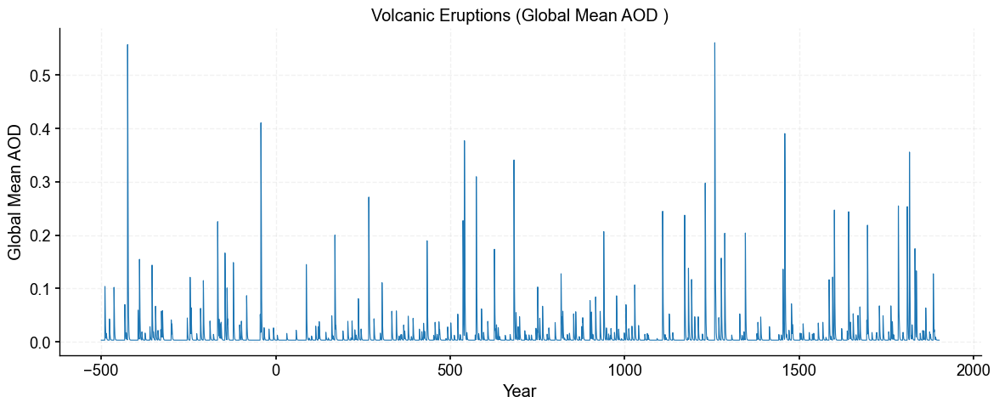

In [9]:

# Plot timeseries
plt.figure(figsize=(14, 5))
plt.plot(ds.time, gm_aod, linewidth=0.8)
plt.xlabel('Year')
plt.ylabel('Global Mean AOD')
plt.title('Volcanic Eruptions (Global Mean AOD )')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
import numpy as np
import xarray as xr
import pandas as pd

# gm_aod: global mean monthly AOD (DataArray with coord 'time' = float years)

# 1) Build an integer year array from the float years
year_int = np.floor(gm_aod['time'].values).astype(int)

# 2) Make a "year" DataArray to group by
year_da = xr.DataArray(
    year_int,
    coords={'time': gm_aod['time']},
    dims='time',
    name='year'
)

# 3) Group by year and take annual max AOD
gm_aod_annual = gm_aod.groupby(year_da).max('time')

# Extract years and values
years = gm_aod_annual['year'].values.astype(int)  # new group-by dim is 'year'
vals  = gm_aod_annual.values


In [11]:
def pick_top_events(years, values, min_sep_years=3, max_events=30):
    # Remove negative years BEFORE any ranking logic
    mask = years > 0
    years_f = years[mask]
    values_f = values[mask]

    # Sort descending by AOD
    order = np.argsort(values_f)[::-1]

    chosen_years = []
    chosen_vals  = []
    
    for idx in order:
        y = years_f[idx]
        v = values_f[idx]
        
        if not chosen_years:
            ok = True
        else:
            diffs = np.abs(y - np.array(chosen_years))
            ok = np.all(diffs > min_sep_years)
        
        if ok:
            chosen_years.append(y)
            chosen_vals.append(v)
            if max_events is not None and len(chosen_years) >= max_events:
                break
    
    return np.array(chosen_years), np.array(chosen_vals)


In [12]:
top30_years, top30_vals = pick_top_events(years, vals,
                                          min_sep_years=5,
                                          max_events=30)

top20_years, top20_vals = pick_top_events(years, vals,
                                          min_sep_years=5,
                                          max_events=20)

top10_years, top10_vals = pick_top_events(years, vals,
                                          min_sep_years=5,
                                          max_events=10)

top30_df = pd.DataFrame({'year': top30_years, 'aod550': top30_vals})
top20_df = pd.DataFrame({'year': top20_years, 'aod550': top20_vals})
top10_df = pd.DataFrame({'year': top10_years, 'aod550': top10_vals})


Text(0.5, 1.0, 'Top 30 Volcanic Eruptions')

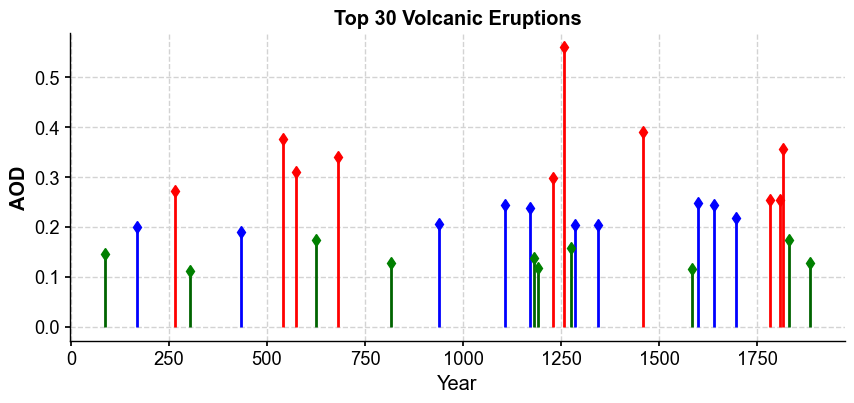

In [13]:
top10 = top10_df
top20_only = top20_df[~top20_df['year'].isin(top10_df['year'])]
top30_only = top30_df[~top30_df['year'].isin(top20_df['year'])]


fig, ax = plt.subplots(figsize=(10,4))

# Top 10 → red
ax.stem(
    top10['year'], top10['aod550'],
    linefmt='r-', markerfmt='rd', basefmt=" "
)

# Top 20 (not in top 10) → blue
ax.stem(
    top20_only['year'], top20_only['aod550'],
    linefmt='b-', markerfmt='bd', basefmt=" "
)

# Top 30 (not in top 20) → black
ax.stem(
    top30_only['year'], top30_only['aod550'],
    linefmt='darkgreen', markerfmt='gd', basefmt=" "
)

ax.set_xlabel('Year')
ax.set_ylabel('AOD', fontweight='bold')
ax.set_title('Top 30 Volcanic Eruptions', fontweight='bold')


In [14]:
top10_df

,year,aod550
0,1257,0.560890
1,1458,0.390554
2,540,0.377009
3,1815,0.355701
4,682,0.340885
5,574,0.309609
6,1230,0.297440
7,266,0.271279
8,1784,0.254801
9,1809,0.253502


## Superposed Epoch Analysis

In [15]:
def field_sea(yr, fd):
    
    fd0 = fd[str(yr)]
    bl_mean = fd[str(yr-3):str(yr)].da.mean(dim='time') # mean field pre-eruption
    mean_field = cfr.ClimateField(bl_mean)

    sea_list = []
    for lag in range(-3, 7):  
        year_field = fd[str(yr + lag)]
        demeaned = year_field - mean_field
        sea_list.append(demeaned.da) 

    # make lag coordinate instead of year CE (for easier composite)
    sea_da = xr.concat(sea_list, dim='time')
    sea_da = sea_da.assign_coords({'time': range(-3, 7)})  
    sea_fd = cfr.ClimateField(sea_da)

    return sea_fd

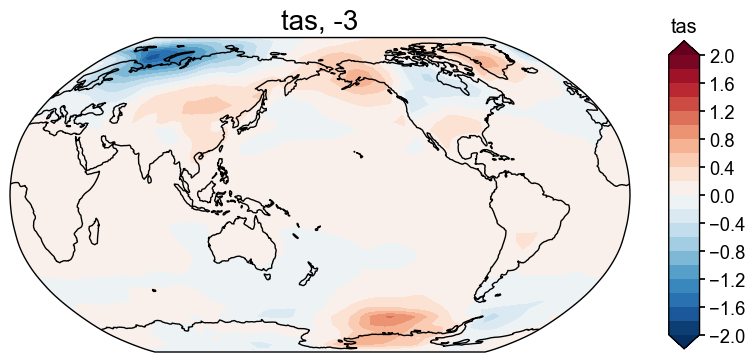

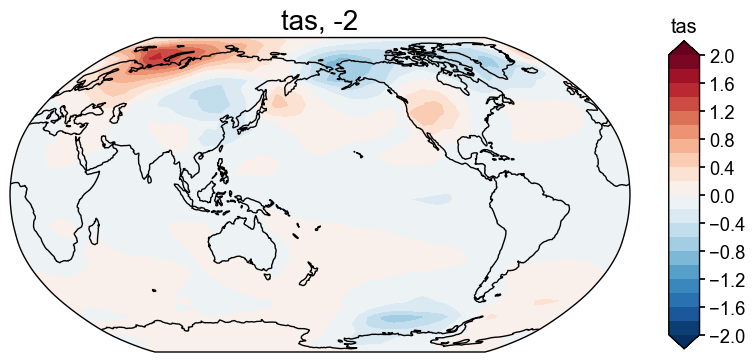

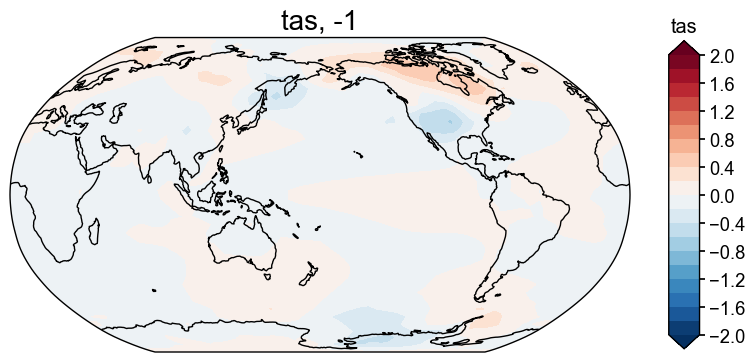

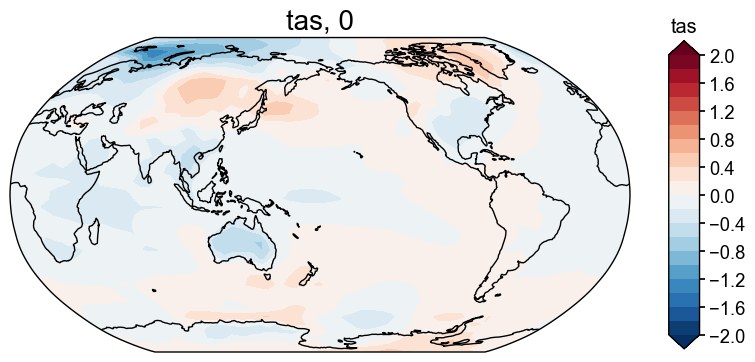

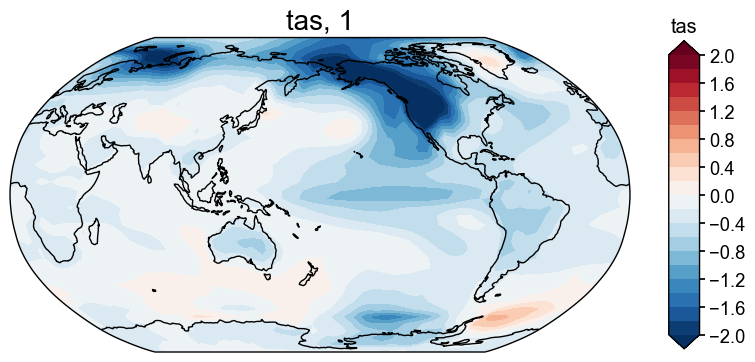

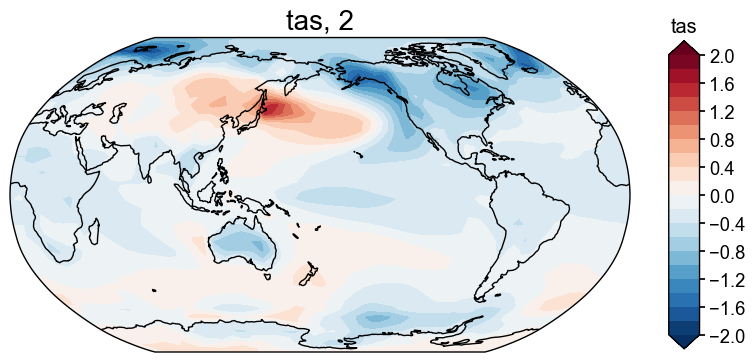

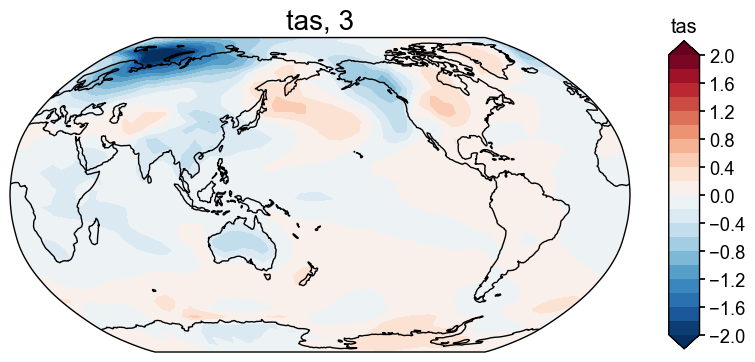

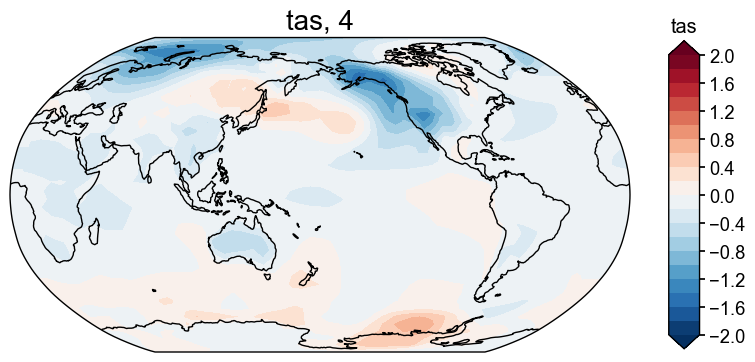

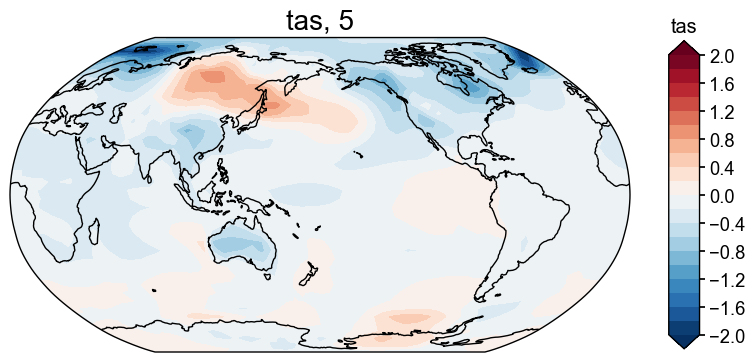

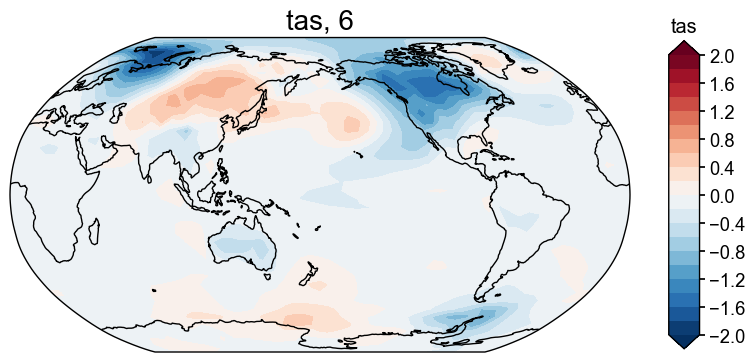

In [16]:
p = field_sea(1600, lmr_fd)

for t in p.da.time.values:
    p[str(t)].plot(levels=np.linspace(-2, 2, 21),       # set levels for the colors
    cbar_labels=np.linspace(-2, 2, 11))

In [17]:
def composite_sea(eruption_years, fd):
  
    sea_list = []
    for yr in eruption_years:
        sea_fd = field_sea(yr, fd)
        sea_list.append(sea_fd.da)
    
    # Stack along eruption dimension: shape = (n_eruptions, 10_lags, lat, lon)
    all_eruptions = xr.concat(sea_list, dim='eruption')
    
    # Average across eruptions shape = (10_lags, lat, lon)
    composite_da = all_eruptions.mean(dim='eruption')
    
    # time coordinates to lag year instead of years CE
    composite_da = composite_da.assign_coords({'time': range(-3, 7)})
    
    composite_fd = cfr.ClimateField(composite_da)
    
    return composite_fd


In [18]:
# Save LMR composites

top10_composite_lmr = composite_sea(top10_years, lmr_fd)
top20_composite_lmr = composite_sea(top20_years, lmr_fd)
top30_composite_lmr = composite_sea(top30_years, lmr_fd)

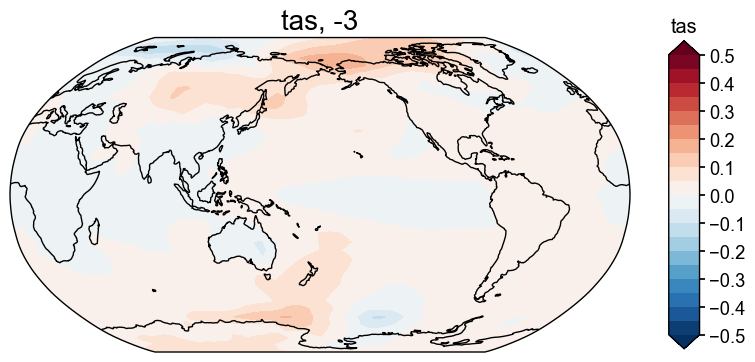

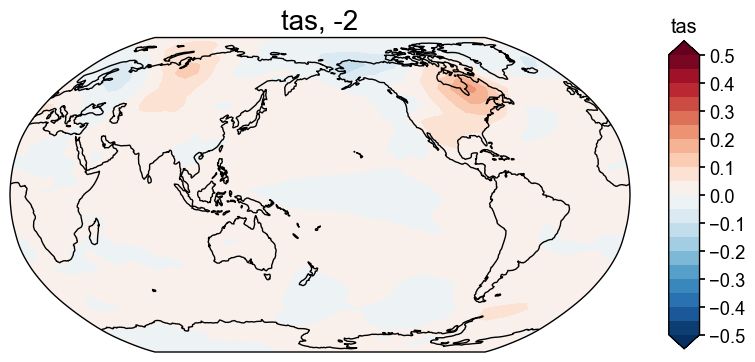

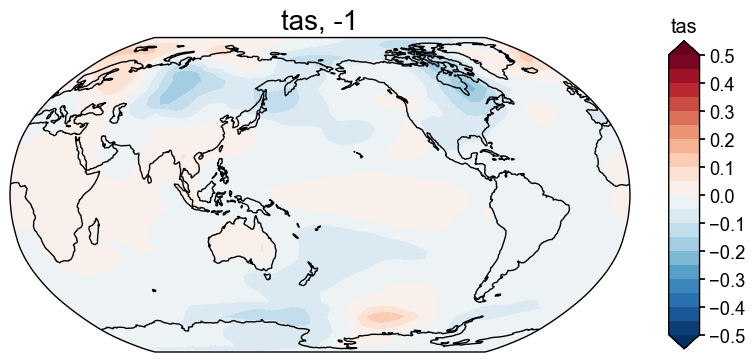

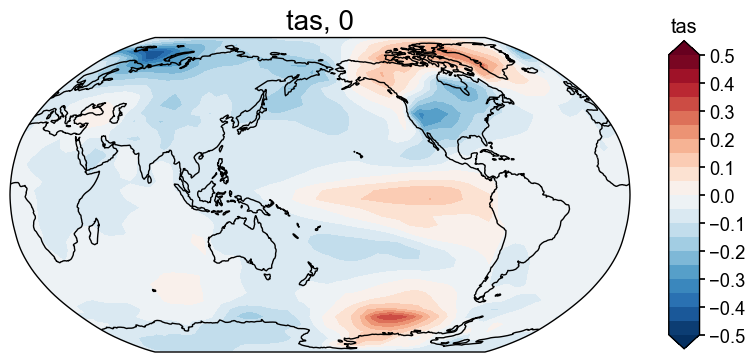

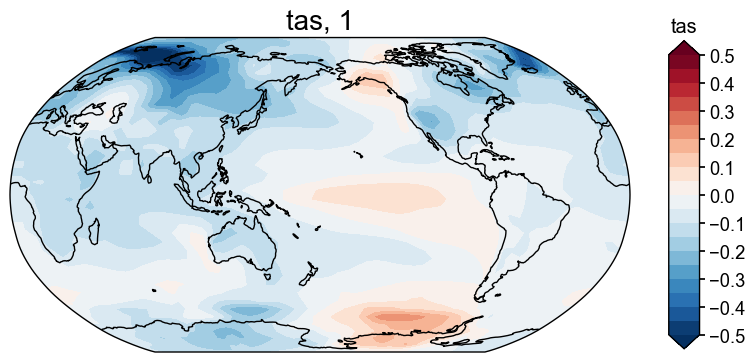

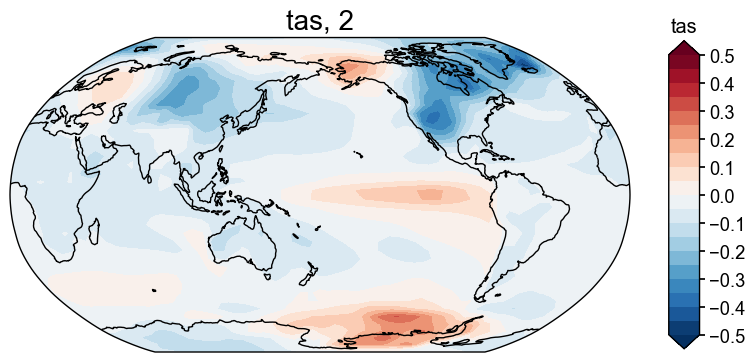

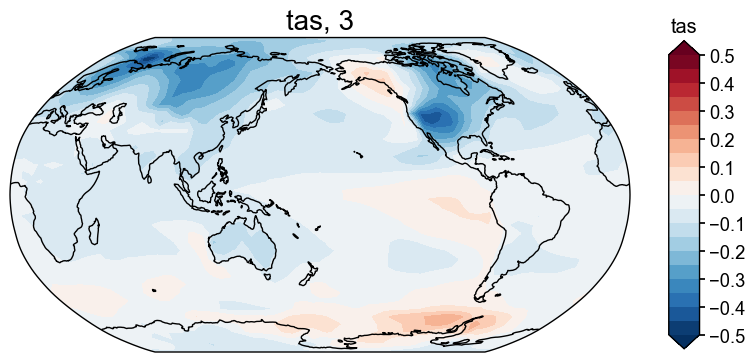

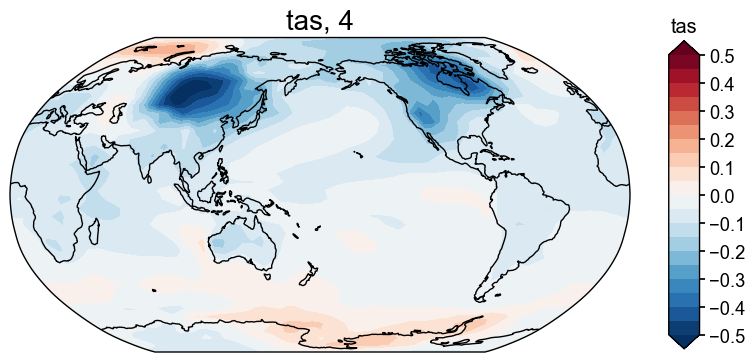

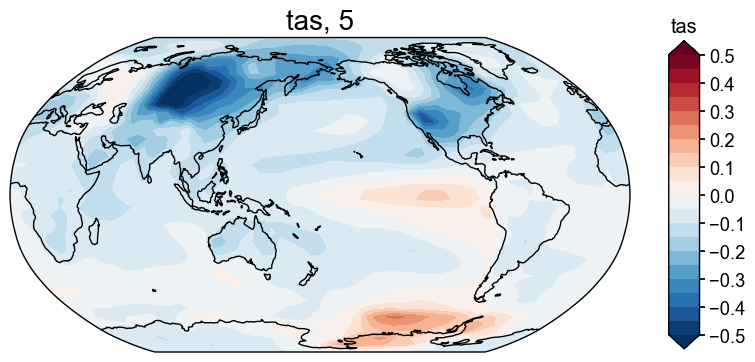

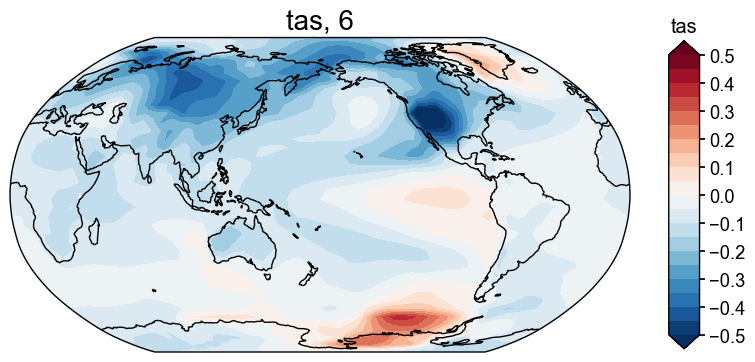

In [16]:
# TEesting

for i in top10_composite_lmr.da.time.values:
    top10_composite_lmr[str(i)].plot(levels=np.linspace(-0.5, 0.5, 21),       # set levels for the colors
    cbar_labels=np.linspace(-0.5, 0.5, 11),
    extend='both')

## Bootstrapping

In [24]:
def bootstrap(df, fd, before=3, after=6, n_perm=1000):
   
    # Get volcanic years
    volc_yrs = df['year'].values
    
    # Get all years
    all_years = fd.da.time.values
    
    # exclude years between (-3,+6) of any volcanic year
    eruption_window_years = []
    for volc_yr in volc_yrs:
        # Exclude years from [volc_yr - before] to [volc_yr + after]
        window = np.arange(volc_yr - before, volc_yr + after + 1)
        eruption_window_years.extend(window)
    
    eruption_window_years = np.unique(eruption_window_years)
    
    # Define non-volcanic years
    # Exclude: eruption windows AND years too close to start/end of record
    min_year = all_years.min() + before
    max_year = all_years.max() - after
    
    non_erup = []
    for yr in all_years:
        if (yr not in eruption_window_years) and (yr >= min_year) and (yr <= max_year):
            non_erup.append(yr)
    
    non_erup = np.array(non_erup)
    
    print(f"Total years: {len(all_years)}")
    print(f"Volcanic eruptions: {len(volc_yrs)}")
    print(f"Years in eruption windows: {len(eruption_window_years)}")
    print(f"Non-volcanic years available: {len(non_erup)}")
    
    # Store bootstrap composites
    bootstrap_composites = []
    
    for i in range(n_perm):
        print(f"Computing SEA random realization #{i+1}/{n_perm}")
        
        # Randomly sample non-volcanic years (same number as actual eruptions)
        rnd_yrs = np.random.choice(non_erup, len(volc_yrs), replace=False)
        
        # Create composite for these random years
        composite_bs = composite_sea(rnd_yrs, fd)
        
        # Store this bootstrap composite
        bootstrap_composites.append(composite_bs.da.values)
    
    # Stack into array: shape (n_perm, n_lags, lat, lon)
    bootstrap_composites = np.stack(bootstrap_composites, axis=0)
    
    
    return bootstrap_composites, non_erup


### For LMR Reproduced

In [21]:
### ----- FOR TOP 10 -----------
bc_10_lmr, no_erup_10_lmr = bootstrap(top10_df, lmr_fd, before=3, after=6, n_perm=1000)

# calculate significance for 95% CI
ci_lo_10_lmr = np.percentile(bc_10_lmr, 2.5, axis=0)   # shape: (n_lags, lat, lon)
ci_up_10_lmr = np.percentile(bc_10_lmr, 97.5, axis=0)  # shape: (n_lags, lat, lon)

### ----- FOR TOP 20 -----------
bc_20_lmr, no_erup_20_lmr = bootstrap(top20_df, lmr_fd, before=3, after=6, n_perm=1000)

# calculate significance for 95% CI
ci_lo_20_lmr = np.percentile(bc_20_lmr, 2.5, axis=0)   # shape: (n_lags, lat, lon)
ci_up_20_lmr = np.percentile(bc_20_lmr, 97.5, axis=0)  # shape: (n_lags, lat, lon)

### ----- FOR TOP 30 -----------
bc_30_lmr, no_erup_30_lmr = bootstrap(top30_df, lmr_fd, before=3, after=6, n_perm=1000)

# calculate significance for 95% CI
ci_lo_30_lmr = np.percentile(bc_30_lmr, 2.5, axis=0)   # shape: (n_lags, lat, lon)
ci_up_30_lmr = np.percentile(bc_30_lmr, 97.5, axis=0)  # shape: (n_lags, lat, lon)



Total years: 2000
Volcanic eruptions: 10
Years in eruption windows: 96
Non-volcanic years available: 1895
Computing SEA random realization #1/1000
Computing SEA random realization #2/1000
Computing SEA random realization #3/1000
Computing SEA random realization #4/1000
Computing SEA random realization #5/1000
Computing SEA random realization #6/1000
Computing SEA random realization #7/1000
Computing SEA random realization #8/1000
Computing SEA random realization #9/1000
Computing SEA random realization #10/1000
Computing SEA random realization #11/1000
Computing SEA random realization #12/1000
Computing SEA random realization #13/1000
Computing SEA random realization #14/1000
Computing SEA random realization #15/1000
Computing SEA random realization #16/1000
Computing SEA random realization #17/1000
Computing SEA random realization #18/1000
Computing SEA random realization #19/1000
Computing SEA random realization #20/1000
Computing SEA random realization #21/1000
Computing SEA random 

### Comparing against eruption composites

In [22]:
# get T/F fields for significant or not 

### ------ TOP 10 -----------
volc_comp_10_lmr = top10_composite_lmr.da.values

sig_cool_10_lmr = volc_comp_10_lmr < ci_lo_10_lmr
sig_warm_10_lmr = volc_comp_10_lmr > ci_up_10_lmr

### ------- TOP 20 ------------
volc_comp_20_lmr = top20_composite_lmr.da.values

sig_cool_20_lmr = volc_comp_20_lmr < ci_lo_20_lmr
sig_warm_20_lmr = volc_comp_20_lmr > ci_up_20_lmr

### -------- TOP 30 ----------
volc_comp_30_lmr = top30_composite_lmr.da.values

sig_cool_30_lmr = volc_comp_30_lmr < ci_lo_30_lmr
sig_warm_30_lmr = volc_comp_30_lmr > ci_up_30_lmr

In [23]:
sig_cool_10_lmr

array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, Fal

In [25]:
def plot_comp_with_null(comp_fd, warm, cool, name):    
    for lag_idx in range(0,10):
        # mak climatefield object
        volcanic_field = cfr.ClimateField(comp_fd.da.isel(time=lag_idx))

        # Separate masks for cooling and warming
        sig_cooling_mask = cool[lag_idx, :, :]  # 2D mask for significant cooling
        sig_warming_mask = warm[lag_idx, :, :]  # 2D mask for significant warming

        # Plot
        fig, ax = volcanic_field.plot(
            levels=np.linspace(-0.5, 0.5, 21),
            cbar_labels=np.linspace(-0.5, 0.5, 11),
            extend='both'
        )

        # Get lat/lon grids
        lat = volcanic_field.da.lat.values
        lon = volcanic_field.da.lon.values
        lon_2d, lat_2d = np.meshgrid(lon, lat)

        import cartopy.crs as ccrs

        # Blue dots for cooling
        cooling_lats = lat_2d[sig_cooling_mask]
        cooling_lons = lon_2d[sig_cooling_mask]
        ax.scatter(cooling_lons, cooling_lats, s=5, c='darkgray', alpha=0.7, marker='.', 
                transform=ccrs.PlateCarree(), )

        # Red dots for warming
        warming_lats = lat_2d[sig_warming_mask]
        warming_lons = lon_2d[sig_warming_mask]
        ax.scatter(warming_lons, warming_lats, s=5, c='darkgray', alpha=0.7, marker='.', 
                transform=ccrs.PlateCarree())

        ax.legend(loc='lower left')
        plt.title(f'{name} Top {len(comp_fd.da)} Composite, Year {lag_idx-3} ')

        plt.show()

        print(f"Significant cooling: {sig_cooling_mask.sum()}")
        print(f"Significant warming: {sig_warming_mask.sum()}")

In [26]:
def plot_comp_with_null_ins(comp_fd, warm, cool, name):    
    for lag_idx in range(0,10):
        # make climatefield object
        volcanic_field = cfr.ClimateField(comp_fd.da.isel(time=lag_idx))

        # Separate masks for cooling and warming
        sig_cooling_mask = cool[lag_idx, :, :]  # 2D mask for significant cooling
        sig_warming_mask = warm[lag_idx, :, :]  # 2D mask for significant warming
        
        # Create insignificant mask (neither cooling nor warming)
        insig_mask = ~(sig_cooling_mask | sig_warming_mask)

        # Plot
        fig, ax = volcanic_field.plot(
            levels=np.linspace(-0.5, 0.5, 21),
            cbar_labels=np.linspace(-0.5, 0.5, 11),
            extend='both'
        )

        # Get lat/lon grids
        lat = volcanic_field.da.lat.values
        lon = volcanic_field.da.lon.values
        lon_2d, lat_2d = np.meshgrid(lon, lat)

        import cartopy.crs as ccrs

        plt.rcParams['hatch.color'] = 'gray'  # or 'silver', 'gainsboro', '#CCCCCC'
        plt.rcParams['hatch.linewidth'] = 0.5  # Make lines thinner too

        # --- Add DOTTING for insignificant regions ---
        ax.contourf(lon, lat, insig_mask.astype(float), 
                    levels=[0.5, 1.5], 
                    colors='none',
                    hatches = ['..'],
                    transform=ccrs.PlateCarree(),
                    alpha=0)

        

        # Add hatching to legend
        from matplotlib.patches import Patch
        insig_patch = Patch(facecolor='none', edgecolor='darkgray', hatch='...', 
                           )
        
        handles, labels = ax.get_legend_handles_labels()
        handles.append(insig_patch)
        
    


        plt.title(f'{name} Top 30 Composite, Year {lag_idx-3}')

        # Change colorbar title
        cbar_ax = fig.axes[-1]  # Get colorbar axis
        cbar_ax.set_title(r'$T$', pad=15)
        plt.show()

        print(f"Significant cooling: {sig_cooling_mask.sum()}")
        print(f"Significant warming: {sig_warming_mask.sum()}")
        print(f"Not significant: {insig_mask.sum()}")

## Field Comparison

In [27]:
def plot_difference(comp_fd1, comp_fd2, warm1, cool1, warm2, cool2, field1_name, field2_name, pdb):
    """
    Plot differences in significance between two fields.
    
    Parameters:
    -----------
    comp_fd1, comp_fd2 : composite fields (for background difference map)
    warm1, cool1 : significance masks for field 1
    warm2, cool2 : significance masks for field 2
    """
    for lag_idx in range(0, 10):
        # Create difference field for background
        diff_data = comp_fd1.da.isel(time=lag_idx) - comp_fd2.da.isel(time=lag_idx)
        diff_field = cfr.ClimateField(diff_data)
        
        # Get significance masks for this lag
        sig_cooling1 = cool1[lag_idx, :, :]
        sig_warming1 = warm1[lag_idx, :, :]
        sig_cooling2 = cool2[lag_idx, :, :]
        sig_warming2 = warm2[lag_idx, :, :]
        
        # Find differences: significant in one but not the other
        # Cooling: sig in field1 but not field2, OR sig in field2 but not field1
        cooling_diff = (sig_cooling1 & ~sig_cooling2) | (~sig_cooling1 & sig_cooling2)
        
        # Warming: sig in field1 but not field2, OR sig in field2 but not field1
        warming_diff = (sig_warming1 & ~sig_warming2) | (~sig_warming1 & sig_warming2)
        
        # Plot difference field as background
        fig, ax = diff_field.plot(
            levels=np.linspace(-0.2, 0.2, 21),
            cbar_labels=np.linspace(-0.2, 0.2, 11),
            proxydb = pdb,
            plot_proxydb = True,
            plot_proxydb_lgd=False,
            cmap='RdBu_r',
            extend='both'
        )
        
        # Get lat/lon grids
        lat = diff_field.da.lat.values
        lon = diff_field.da.lon.values
        lon_2d, lat_2d = np.meshgrid(lon, lat)
        
        import cartopy.crs as ccrs
        
        # Blue dots for cooling differences
        cooling_lats = lat_2d[cooling_diff]
        cooling_lons = lon_2d[cooling_diff]
        ax.scatter(cooling_lons, cooling_lats, s=5, c='blue', alpha=0.7, marker='.', 
                   transform=ccrs.PlateCarree(),)
        
        # Red dots for warming differences
        warming_lats = lat_2d[warming_diff]
        warming_lons = lon_2d[warming_diff]
        ax.scatter(warming_lons, warming_lats, s=5, c='red', alpha=0.7, marker='.', 
                   transform=ccrs.PlateCarree(), )
        
        

        plt.title(f'Response Difference ({field1_name} - {field2_name}), Year {lag_idx-3}')
        cbar = fig.axes[-1]  # colorbar is typically the last axis
        cbar.set_label(r'$\Delta T$ (°C)', rotation=270, labelpad=15)
        cbar.set_ylabel(f'{field1_name} - {field2_name} (°C)', rotation=270, labelpad=15)
        
        plt.show()
        
        print(f"Cooling differences: {cooling_diff.sum()}")
        print(f"Warming differences: {warming_diff.sum()}")
        print(f"Points significant (common)  both: Cooling={np.sum(sig_cooling1 & sig_cooling2)}, Warming={np.sum(sig_warming1 & sig_warming2)}")

In [31]:
def plot_difference_ins(comp_fd1, comp_fd2, warm1, cool1, warm2, cool2, field1_name, field2_name, pdb):
    """
    Plot differences in significance between two fields.
    Dots show where insignificance DIFFERS between fields (XOR of insignificance).
    Blank areas show where both fields agree (both significant OR both insignificant).
    
    Parameters:
    -----------
    comp_fd1, comp_fd2 : composite fields (for background difference map)
    warm1, cool1 : significance masks for field 1
    warm2, cool2 : significance masks for field 2
    """
    for lag_idx in range(0, 10):
        # Create difference field for background
        diff_data = comp_fd1.da.isel(time=lag_idx) - comp_fd2.da.isel(time=lag_idx)
        diff_field = cfr.ClimateField(diff_data)
        
        # Get significance masks for this lag
        sig_cooling1 = cool1[lag_idx, :, :]
        sig_warming1 = warm1[lag_idx, :, :]
        sig_cooling2 = cool2[lag_idx, :, :]
        sig_warming2 = warm2[lag_idx, :, :]
        
        # Get INsignificance masks (inverse of significance)
        insig_cooling1 = ~sig_cooling1
        insig_warming1 = ~sig_warming1
        insig_cooling2 = ~sig_cooling2
        insig_warming2 = ~sig_warming2
        
        # Find where INsignificance DIFFERS (XOR)
        # Cooling: insignificant in one but NOT the other
        diff_insig_cooling = (insig_cooling1 & ~insig_cooling2) | (~insig_cooling1 & insig_cooling2)
        
        # Warming: insignificant in one but NOT the other
        diff_insig_warming = (insig_warming1 & ~insig_warming2) | (~insig_warming1 & insig_warming2)
        
        # Combine the difference masks
        diff_insig_combined = diff_insig_cooling | diff_insig_warming
        
        # Plot difference field as background
        fig, ax = diff_field.plot(
            levels=np.linspace(-0.2, 0.2, 21),
            cbar_labels=np.linspace(-0.2, 0.2, 11),
            proxydb=pdb,
            plot_proxydb=False,
            plot_proxydb_lgd=False,
            cmap='RdBu_r',
            extend='both'
        )
        
        # Get lat/lon grids
        lat = diff_field.da.lat.values
        lon = diff_field.da.lon.values
        
        import cartopy.crs as ccrs
        import matplotlib as mpl
        
        # Set hatch color to light gray
        mpl.rcParams['hatch.color'] = 'gray'
        mpl.rcParams['hatch.linewidth'] = 0.5
        
        # Add dotting using contourf (same method as your other function)
        ax.contourf(lon, lat, diff_insig_combined.astype(float), 
                    levels=[0.5, 1.5], 
                    colors='none',
                    hatches=['..'],
                    transform=ccrs.PlateCarree(),
                    alpha=0)
        
        plt.title(f'Response Difference ({field1_name} - {field2_name}), Year {lag_idx-3}')
        
        # Change colorbar title (at the top of colorbar)
        cbar_ax = fig.axes[-1]  # Get colorbar axis
        cbar_ax.set_title(r'$\Delta T$', pad=15)
        
        plt.show()
        
        print(f"Insignificance differs - Cooling: {diff_insig_cooling.sum()}")
        print(f"Insignificance differs - Warming: {diff_insig_warming.sum()}")
        print(f"Both insignificant - Cooling: {np.sum(insig_cooling1 & insig_cooling2)}")
        print(f"Both insignificant - Warming: {np.sum(insig_warming1 & insig_warming2)}")
        print(f"Both significant - Cooling: {np.sum(sig_cooling1 & sig_cooling2)}")
        print(f"Both significant - Warming: {np.sum(sig_warming1 & sig_warming2)}")

## Function testing (modularizing)

In [29]:
def process_field_sea(field_data, field_name, top10_df, top20_df, top30_df, 
                      top10_years, top20_years, top30_years,
                      before=3, after=6, n_perm=1000):
    """
    Process SEA composites and significance testing for all magnitudes of one field.
    
    Parameters
    ----------
    field_data : climate field object
        The reconstruction field (e.g., lmr_fd, pc_fd, dp_fd)
    field_name : str
        Short name for the field (e.g., 'lmr', 'pc', 'dp')
    top10_df, top20_df, top30_df : pd.DataFrame
        DataFrames containing eruption information for each magnitude
    top10_years, top20_years, top30_years : array-like
        Arrays of eruption years for each magnitude
    before, after : int
        Years before/after eruption for compositing
    n_perm : int
        Number of bootstrap permutations
        
    Returns
    -------
    dict
        Dictionary containing all composites, significance masks, and CI bounds
        for magnitudes 10, 20, and 30
    """
    results = {}
    
    # Define magnitudes to loop over
    magnitudes = [
        ('10', top10_df, top10_years),
        ('20', top20_df, top20_years),
        ('30', top30_df, top30_years)
    ]
    
    for mag_label, mag_df, mag_years in magnitudes:
        # Create composite
        composite = composite_sea(mag_years, field_data)
        results[f'top{mag_label}_composite_{field_name}'] = composite
        
        # Bootstrap for significance testing
        bc, no_erup = bootstrap(mag_df, field_data, before=before, after=after, n_perm=n_perm)
        results[f'bc_{mag_label}_{field_name}'] = bc
        results[f'no_erup_{mag_label}_{field_name}'] = no_erup
        
        # Calculate confidence intervals
        ci_lo = np.percentile(bc, 2.5, axis=0)
        ci_up = np.percentile(bc, 97.5, axis=0)
        results[f'ci_lo_{mag_label}_{field_name}'] = ci_lo
        results[f'ci_up_{mag_label}_{field_name}'] = ci_up
        
        # Get significance masks
        volc_comp = composite.da.values
        results[f'volc_comp_{mag_label}_{field_name}'] = volc_comp
        results[f'sig_cool_{mag_label}_{field_name}'] = volc_comp < ci_lo
        results[f'sig_warm_{mag_label}_{field_name}'] = volc_comp > ci_up
    
    return results



In [30]:
# Usage - run once per field:
lmr_results = process_field_sea(lmr_fd, 'lmr', top10_df, top20_df, top30_df,
                                 top10_years, top20_years, top30_years)

# Then for the next field:
pc_results = process_field_sea(pc_fd, 'pc', top10_df, top20_df, top30_df,
                                top10_years, top20_years, top30_years)

# Then for the next field:
dp_results = process_field_sea(dp_fd, 'dp', top10_df, top20_df, top30_df,
                                top10_years, top20_years, top30_years)



Total years: 2000
Volcanic eruptions: 10
Years in eruption windows: 96
Non-volcanic years available: 1895
Computing SEA random realization #1/1000
Computing SEA random realization #2/1000
Computing SEA random realization #3/1000
Computing SEA random realization #4/1000
Computing SEA random realization #5/1000
Computing SEA random realization #6/1000
Computing SEA random realization #7/1000
Computing SEA random realization #8/1000
Computing SEA random realization #9/1000
Computing SEA random realization #10/1000
Computing SEA random realization #11/1000
Computing SEA random realization #12/1000
Computing SEA random realization #13/1000
Computing SEA random realization #14/1000
Computing SEA random realization #15/1000
Computing SEA random realization #16/1000
Computing SEA random realization #17/1000
Computing SEA random realization #18/1000
Computing SEA random realization #19/1000
Computing SEA random realization #20/1000
Computing SEA random realization #21/1000
Computing SEA random 

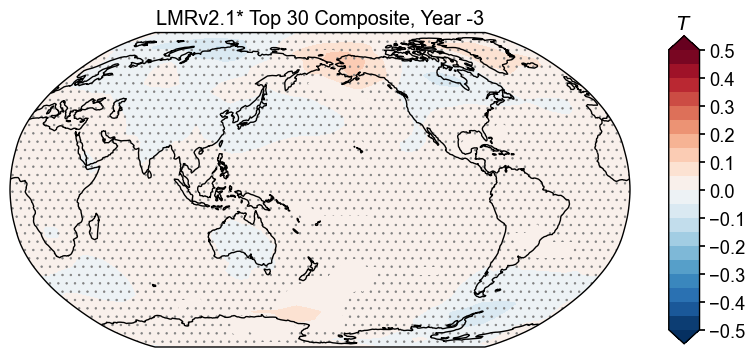

Significant cooling: 0
Significant warming: 159
Not significant: 2487


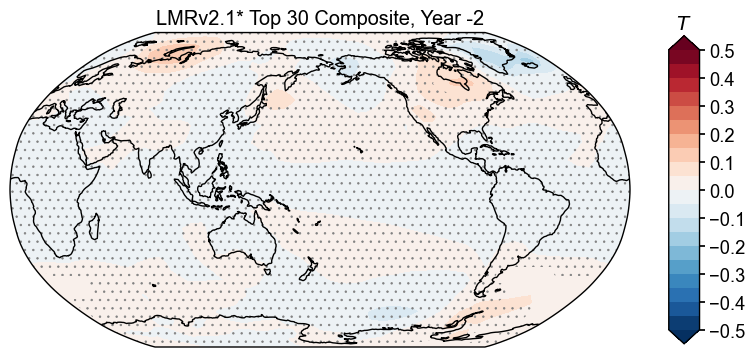

Significant cooling: 26
Significant warming: 144
Not significant: 2476


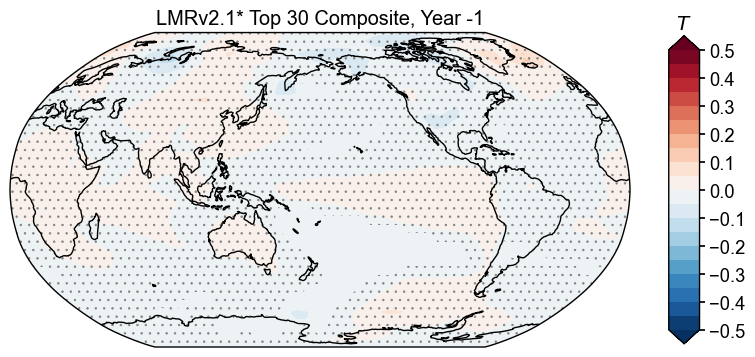

Significant cooling: 237
Significant warming: 0
Not significant: 2409


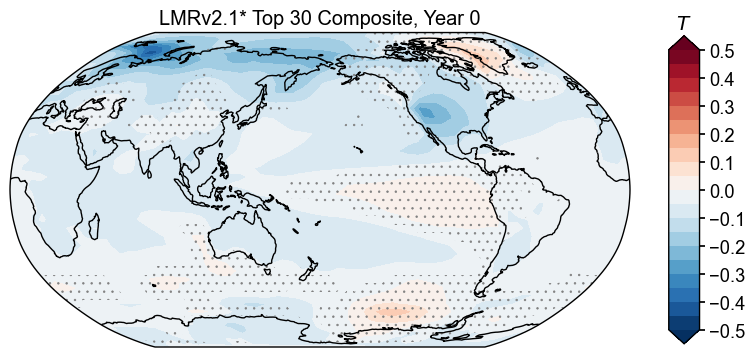

Significant cooling: 1776
Significant warming: 0
Not significant: 870


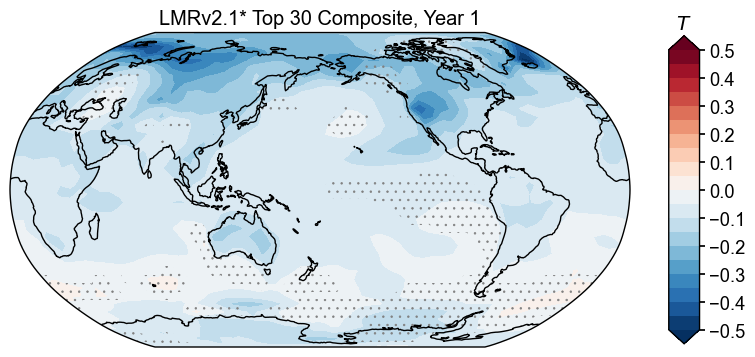

Significant cooling: 2160
Significant warming: 0
Not significant: 486


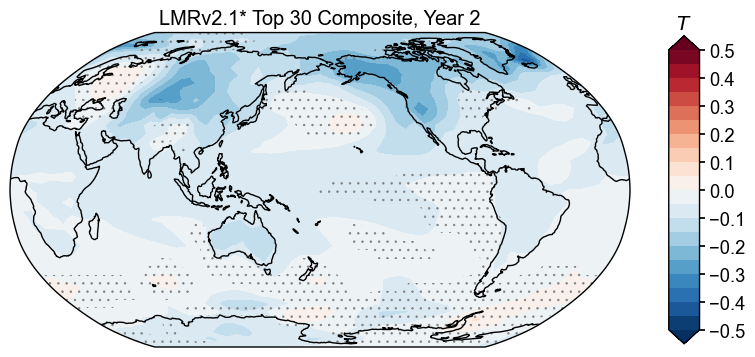

Significant cooling: 1842
Significant warming: 0
Not significant: 804


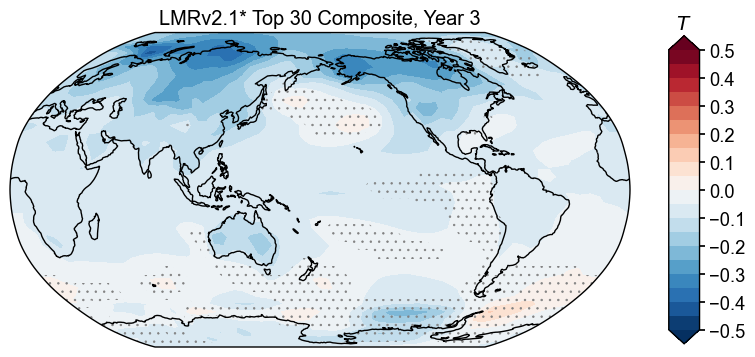

Significant cooling: 2008
Significant warming: 0
Not significant: 638


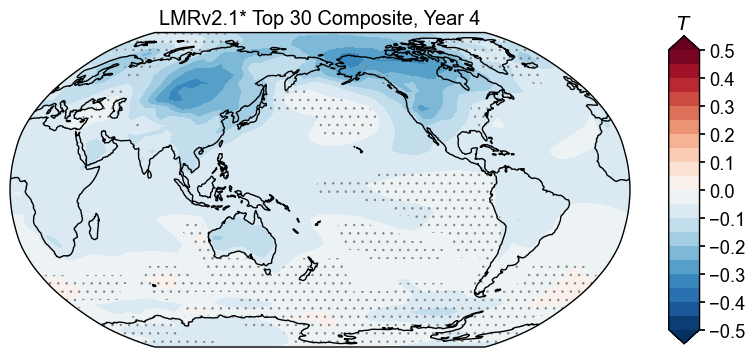

Significant cooling: 1796
Significant warming: 0
Not significant: 850


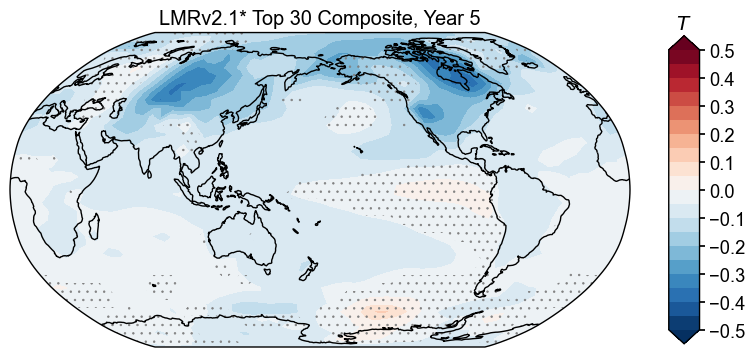

Significant cooling: 1904
Significant warming: 0
Not significant: 742


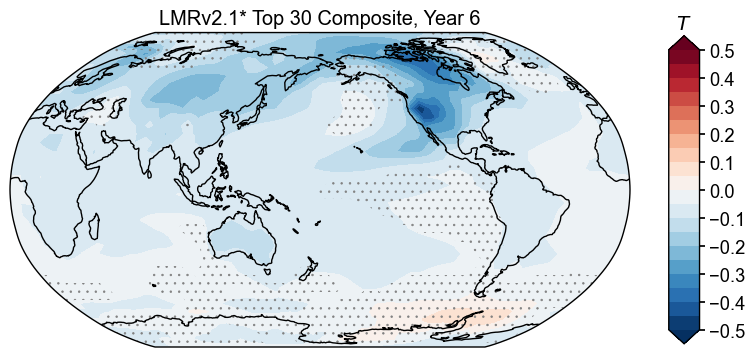

Significant cooling: 1765
Significant warming: 0
Not significant: 881


In [125]:
# Access results exactly as before:
plot_comp_with_null_ins(
    lmr_results['top30_composite_lmr'],
    lmr_results['sig_warm_30_lmr'],
    lmr_results['sig_cool_30_lmr'], 'LMRv2.1*',
)

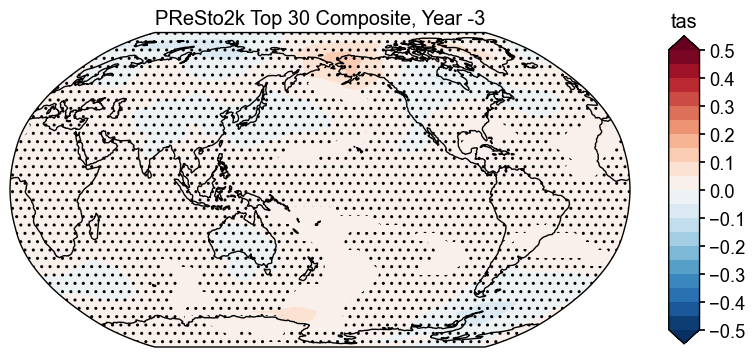

Significant cooling: 0
Significant warming: 297
Not significant: 2349


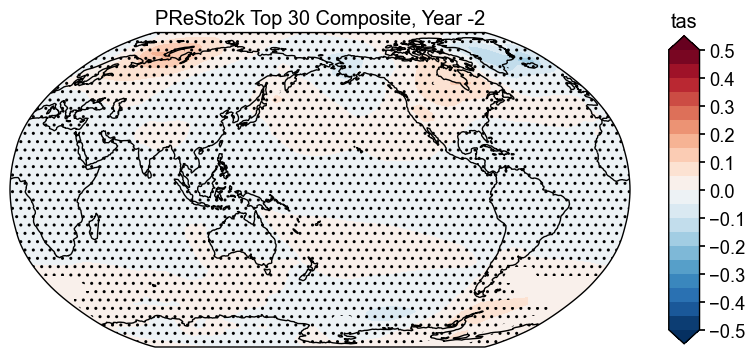

Significant cooling: 19
Significant warming: 112
Not significant: 2515


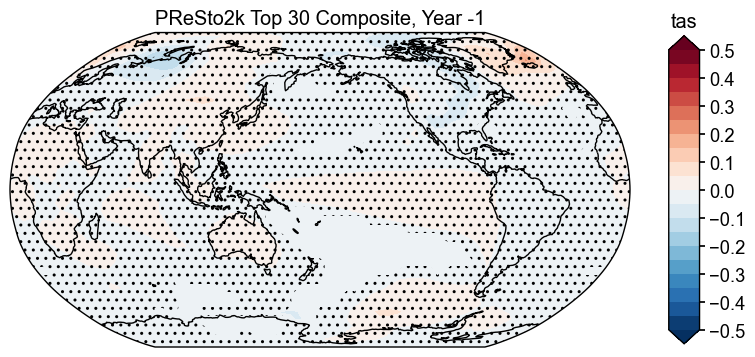

Significant cooling: 262
Significant warming: 0
Not significant: 2384


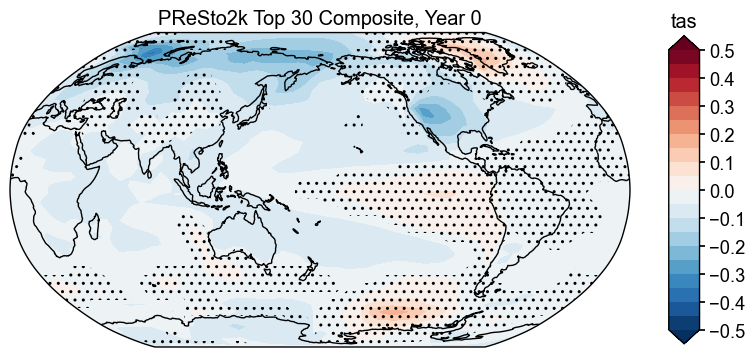

Significant cooling: 1521
Significant warming: 0
Not significant: 1125


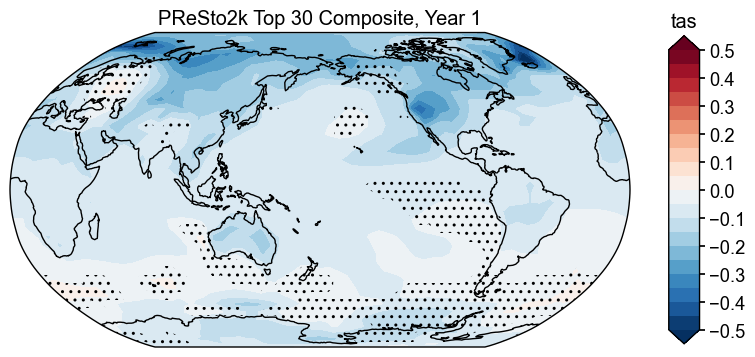

Significant cooling: 2162
Significant warming: 0
Not significant: 484


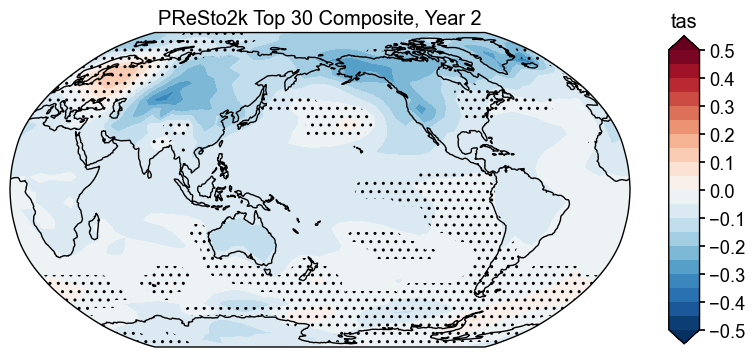

Significant cooling: 1844
Significant warming: 0
Not significant: 802


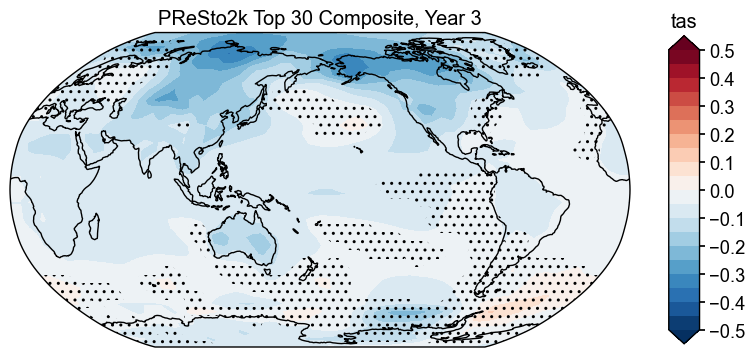

Significant cooling: 1855
Significant warming: 0
Not significant: 791


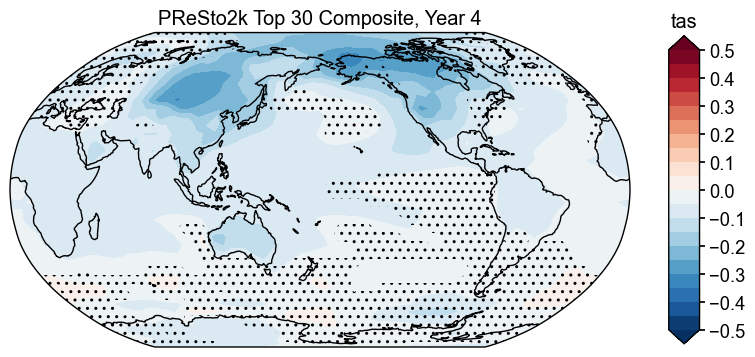

Significant cooling: 1602
Significant warming: 1
Not significant: 1043


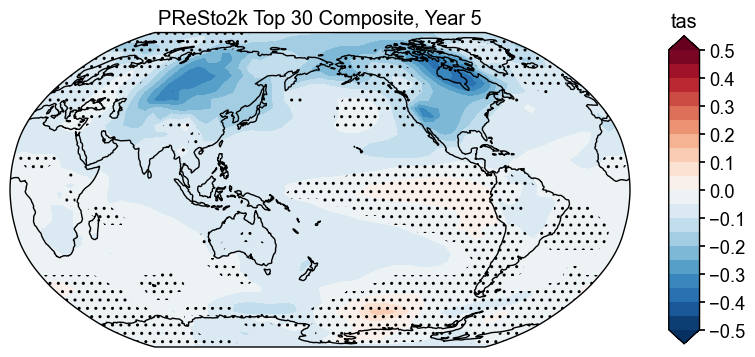

Significant cooling: 1689
Significant warming: 0
Not significant: 957


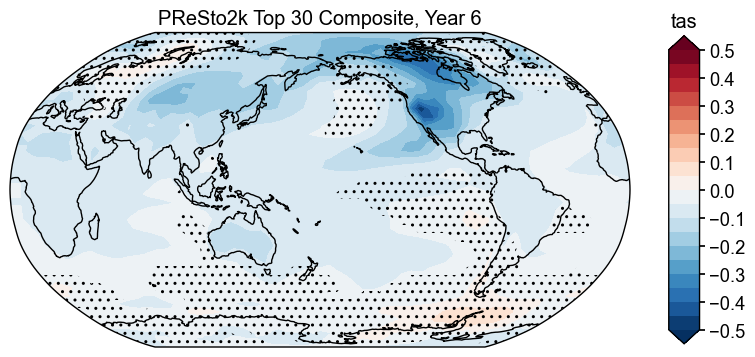

Significant cooling: 1634
Significant warming: 0
Not significant: 1012


In [82]:
plot_comp_with_null_ins(
    pc_results['top30_composite_pc'],
    pc_results['sig_warm_30_pc'],
    pc_results['sig_cool_30_pc'], 'PReSto2k'
)

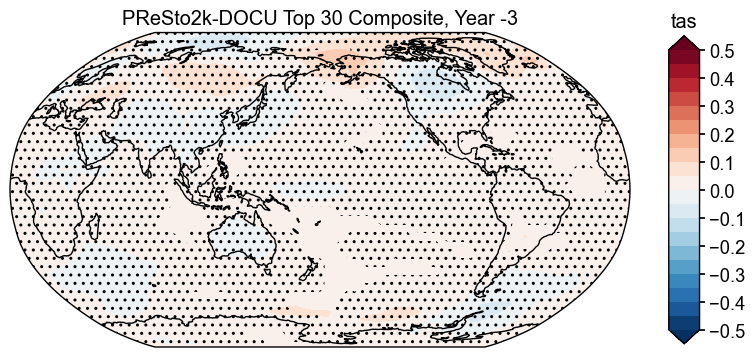

Significant cooling: 0
Significant warming: 244
Not significant: 2402


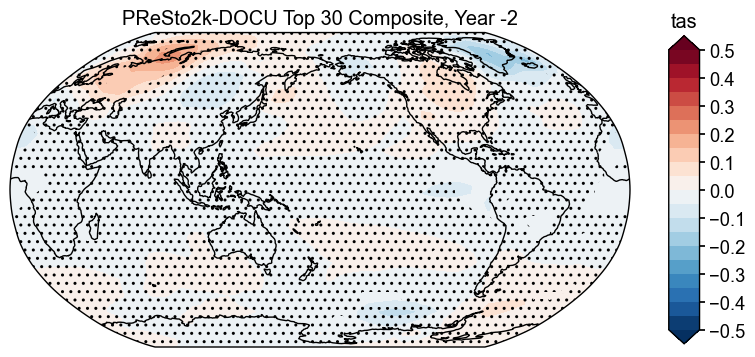

Significant cooling: 138
Significant warming: 50
Not significant: 2458


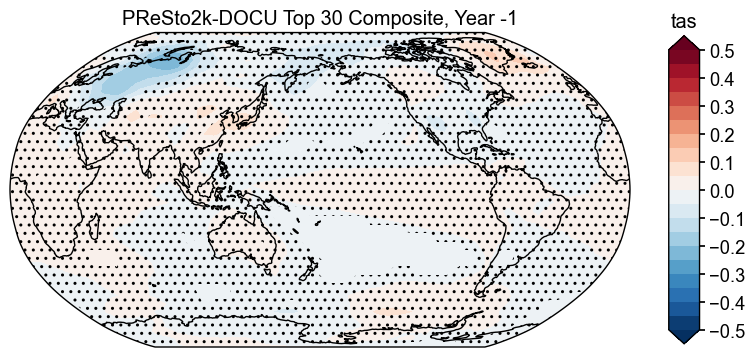

Significant cooling: 234
Significant warming: 14
Not significant: 2398


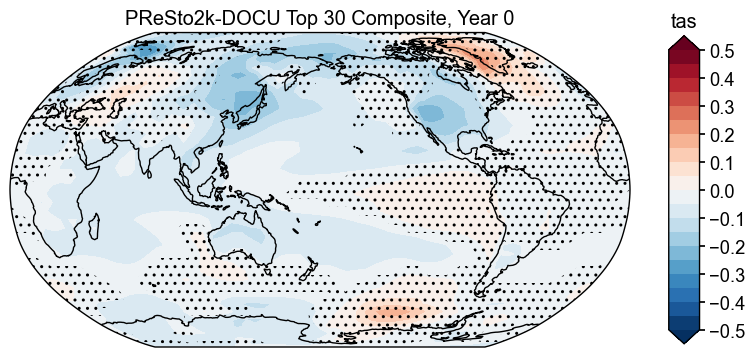

Significant cooling: 1210
Significant warming: 9
Not significant: 1427


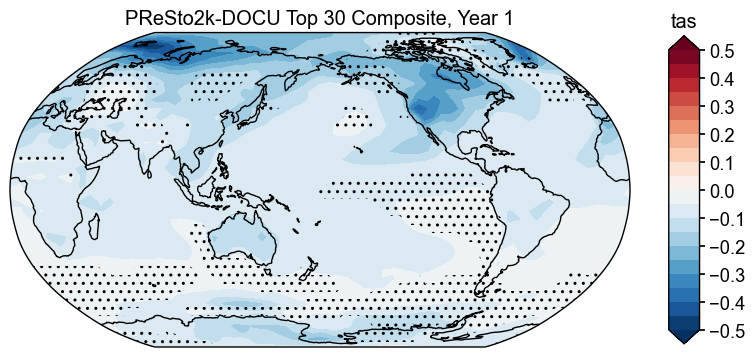

Significant cooling: 1973
Significant warming: 0
Not significant: 673


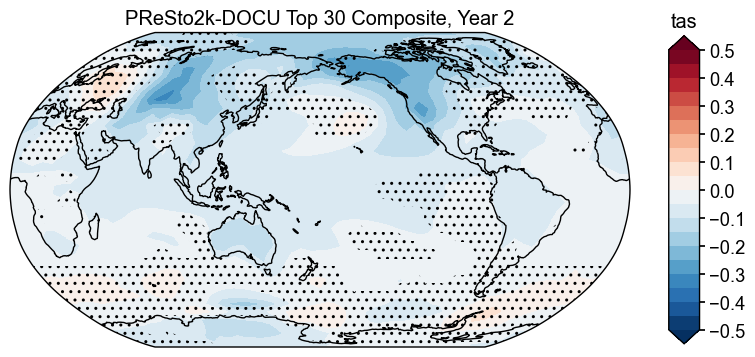

Significant cooling: 1548
Significant warming: 0
Not significant: 1098


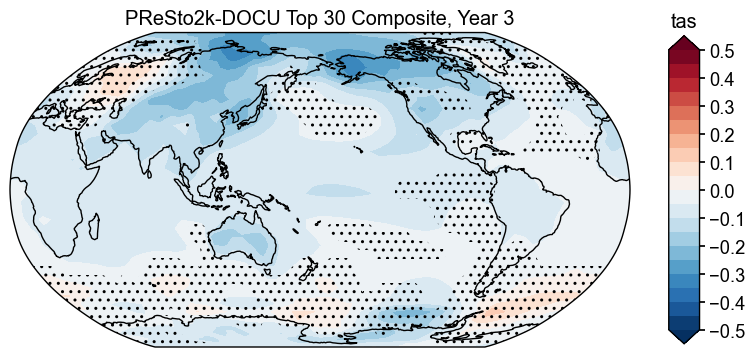

Significant cooling: 1667
Significant warming: 0
Not significant: 979


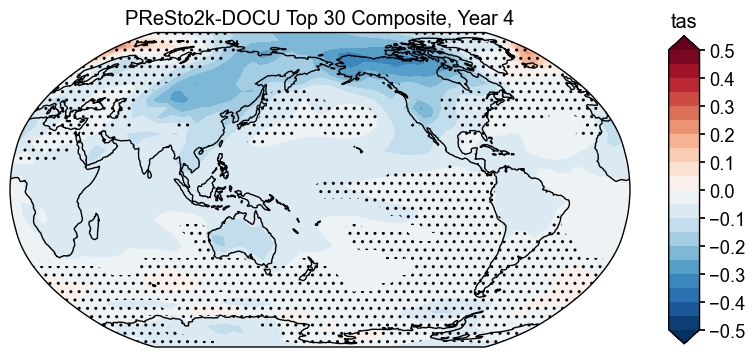

Significant cooling: 1386
Significant warming: 0
Not significant: 1260


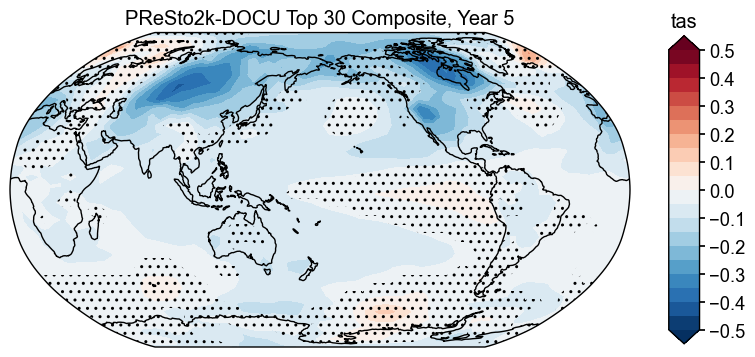

Significant cooling: 1631
Significant warming: 0
Not significant: 1015


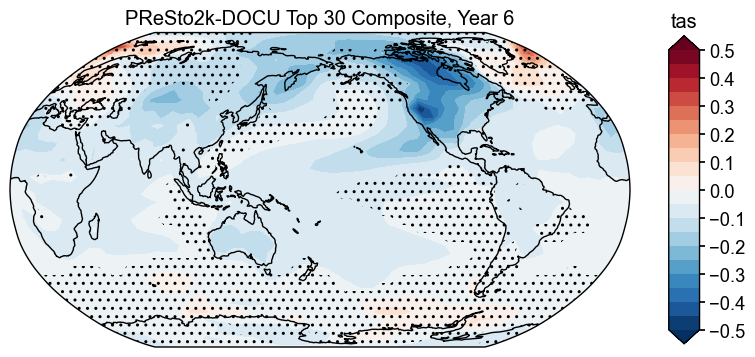

Significant cooling: 1356
Significant warming: 0
Not significant: 1290


In [84]:
plot_comp_with_null_ins(
    dp_results['top30_composite_dp'],
    dp_results['sig_warm_30_dp'],
    dp_results['sig_cool_30_dp'], 'PReSto2k-DOCU'
)

## GMST and NHMT for Year +1

In [61]:
lmr_gmst_yr1 = lmr_results['top10_composite_lmr'][4].da.values.mean()
pc_gmst_yr1 = pc_results['top10_composite_pc'][4].da.values.mean()
dp_gmst_yr1 = dp_results['top10_composite_dp'][4].da.values.mean()

lmr_nhmt_yr1 = lmr_results['top10_composite_lmr'][4].crop(0,90,0,360).da.values.mean()
pc_nhmt_yr1 = pc_results['top10_composite_pc'][4].crop(0,90,0,360).da.values.mean()
dp_nhmt_yr1 = dp_results['top10_composite_dp'][4].crop(0,90,0,360).da.values.mean()

print(f'LMR GMST for Year +1 is: {lmr_gmst_yr1}')
print(f'PReSto2k class GMST for Year +1 is: {pc_gmst_yr1}')
print(f'PReSto2k meta GMST for Year +1 is: {dp_gmst_yr1}')

print(f'LMR NHMT for Year +1 is: {lmr_nhmt_yr1}')
print(f'PReSto2k class NHMT for Year +1 is: {pc_nhmt_yr1}')
print(f'PReSto2k meta NHMT for Year +1 is: {dp_nhmt_yr1}')

LMR GMST for Year +1 is: -0.0828758446177218
PReSto2k class GMST for Year +1 is: -0.08523377858187109
PReSto2k meta GMST for Year +1 is: -0.09262457773327579
LMR NHMT for Year +1 is: -0.12214261107482917
PReSto2k class NHMT for Year +1 is: -0.12626109780257083
PReSto2k meta NHMT for Year +1 is: -0.13753602931644043


In [62]:
def create_summary_table_simple(lmr_results, pc_results, dp_results, year_idx=4):
    """
    Create summary tables of GMST and NHMT values.
    """
    
    gmst_data = []
    nhmt_data = []
    
    # Process each reconstruction
    for field_name, field_short, results in [('LMR', 'lmr', lmr_results), 
                                              ('PReSto2k-class', 'pc', pc_results), 
                                              ('DOCU-PReSto', 'dp', dp_results)]:
        
        gmst_row = [field_name]
        nhmt_row = [field_name]
        
        # Process each magnitude
        for mag in ['10', '20', '30']:
            comp_key = f'top{mag}_composite_{field_short}'
            composite = results[comp_key]
            
            # GMST
            gmst_val = composite[year_idx].da.values.mean()
            gmst_row.append(gmst_val)
            
            # NHMT
            nhmt_val = composite[year_idx].crop(0, 90, 0, 360).da.values.mean()
            nhmt_row.append(nhmt_val)
        
        gmst_data.append(gmst_row)
        nhmt_data.append(nhmt_row)
    
    # Create DataFrames
    columns = ['Reconstruction', 'Top 10', 'Top 20', 'Top 30']
    gmst_df = pd.DataFrame(gmst_data, columns=columns).set_index('Reconstruction')
    nhmt_df = pd.DataFrame(nhmt_data, columns=columns).set_index('Reconstruction')
    
    return gmst_df, nhmt_df




In [45]:
# Usage:
gmst_table, nhmt_table = create_summary_table_simple(lmr_results, pc_results, dp_results, year_idx=4)

print("GMST for Year +1 (°C):")
print(gmst_table.round(3))
print("\nNHMT for Year +1 (°C):")
print(nhmt_table.round(3))


GMST for Year +1 (°C):
                Top 10  Top 20  Top 30
Reconstruction                        
LMR             -0.083  -0.133  -0.109
PReSto2k-class  -0.085  -0.131  -0.107
DOCU-PReSto     -0.093  -0.129  -0.105

NHMT for Year +1 (°C):
                Top 10  Top 20  Top 30
Reconstruction                        
LMR             -0.122  -0.192  -0.153
PReSto2k-class  -0.126  -0.189  -0.150
DOCU-PReSto     -0.138  -0.183  -0.144


## Try DIfference

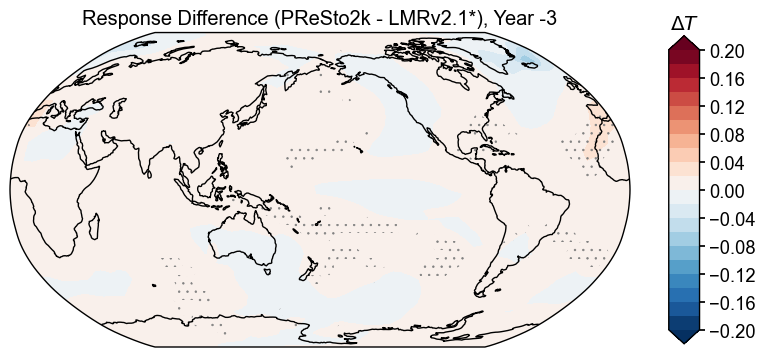

Insignificance differs - Cooling: 0
Insignificance differs - Warming: 160
Both insignificant - Cooling: 2646
Both insignificant - Warming: 2344
Both significant - Cooling: 0
Both significant - Warming: 142


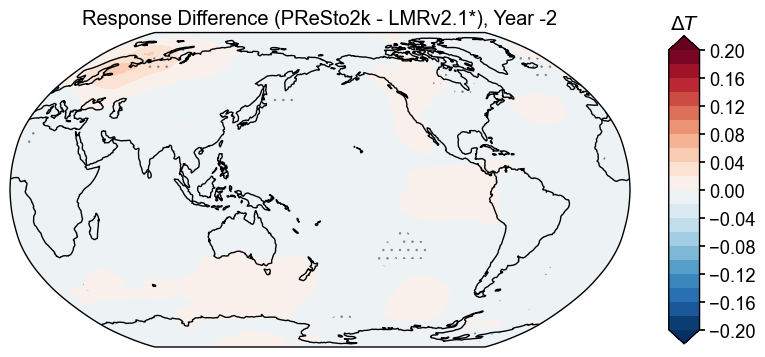

Insignificance differs - Cooling: 17
Insignificance differs - Warming: 48
Both insignificant - Cooling: 2613
Both insignificant - Warming: 2491
Both significant - Cooling: 16
Both significant - Warming: 107


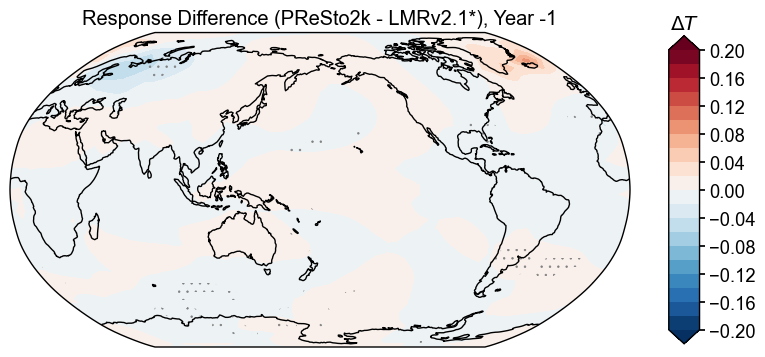

Insignificance differs - Cooling: 87
Insignificance differs - Warming: 0
Both insignificant - Cooling: 2363
Both insignificant - Warming: 2646
Both significant - Cooling: 196
Both significant - Warming: 0


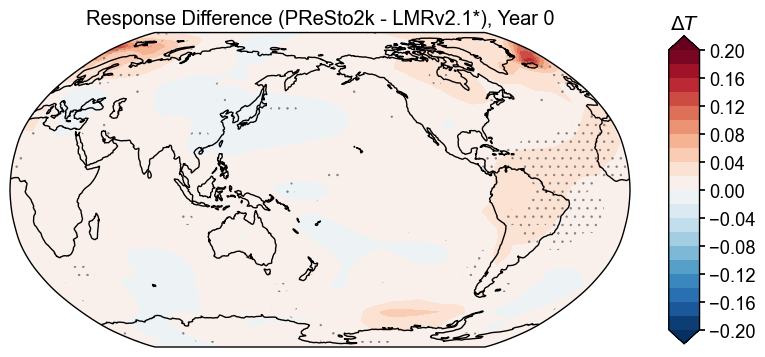

Insignificance differs - Cooling: 255
Insignificance differs - Warming: 0
Both insignificant - Cooling: 867
Both insignificant - Warming: 2646
Both significant - Cooling: 1524
Both significant - Warming: 0


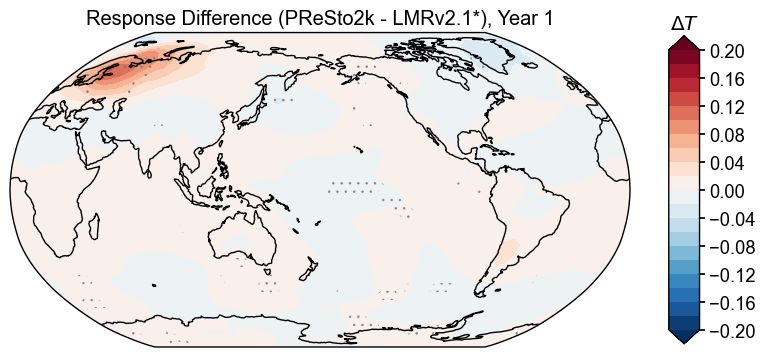

Insignificance differs - Cooling: 122
Insignificance differs - Warming: 0
Both insignificant - Cooling: 407
Both insignificant - Warming: 2646
Both significant - Cooling: 2117
Both significant - Warming: 0


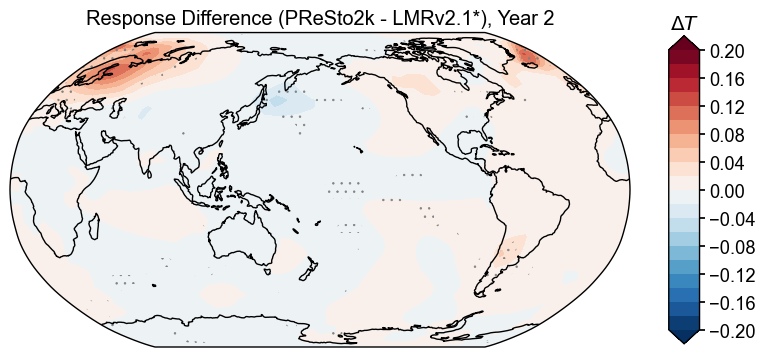

Insignificance differs - Cooling: 149
Insignificance differs - Warming: 0
Both insignificant - Cooling: 711
Both insignificant - Warming: 2646
Both significant - Cooling: 1786
Both significant - Warming: 0


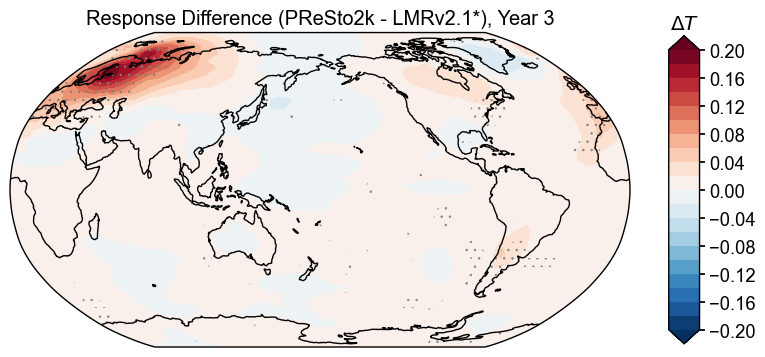

Insignificance differs - Cooling: 212
Insignificance differs - Warming: 0
Both insignificant - Cooling: 599
Both insignificant - Warming: 2646
Both significant - Cooling: 1835
Both significant - Warming: 0


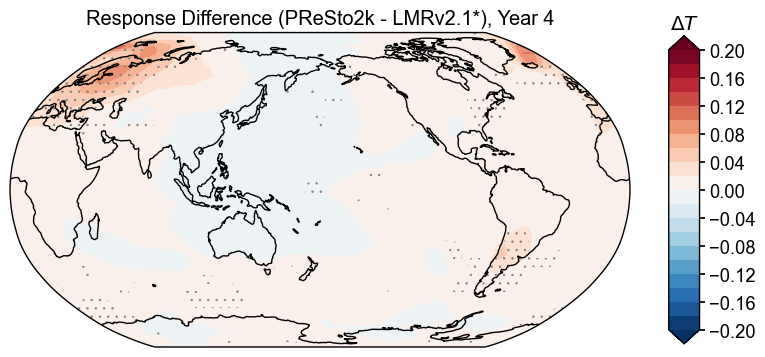

Insignificance differs - Cooling: 253
Insignificance differs - Warming: 1
Both insignificant - Cooling: 825
Both insignificant - Warming: 2645
Both significant - Cooling: 1568
Both significant - Warming: 0


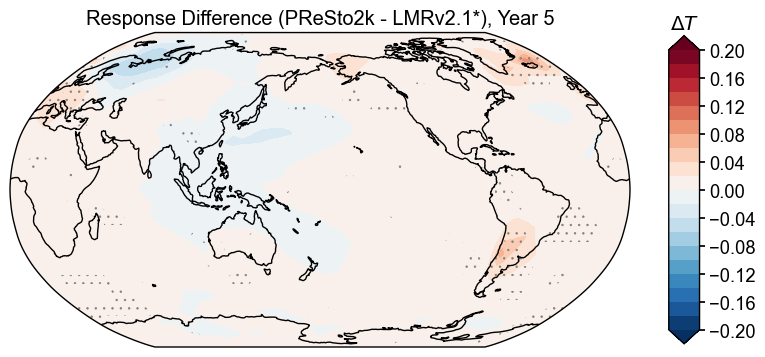

Insignificance differs - Cooling: 200
Insignificance differs - Warming: 0
Both insignificant - Cooling: 727
Both insignificant - Warming: 2646
Both significant - Cooling: 1719
Both significant - Warming: 0


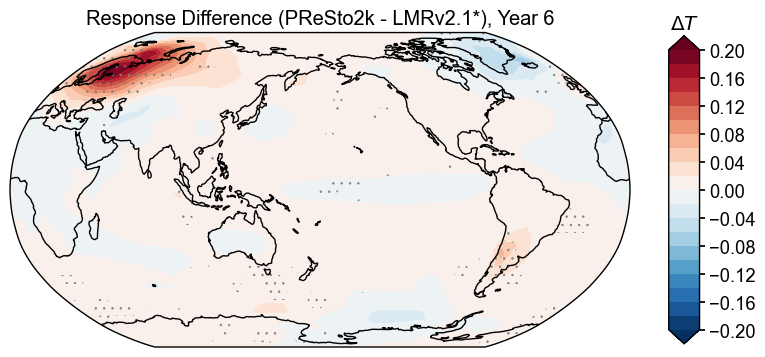

Insignificance differs - Cooling: 195
Insignificance differs - Warming: 0
Both insignificant - Cooling: 845
Both insignificant - Warming: 2646
Both significant - Cooling: 1606
Both significant - Warming: 0


In [32]:
plot_difference_ins(pc_results['top30_composite_pc'], lmr_results['top30_composite_lmr'], pc_results['sig_warm_30_pc'], pc_results['sig_cool_30_pc'], lmr_results['sig_warm_30_lmr'], lmr_results['sig_cool_30_lmr'], 'PReSto2k', 'LMRv2.1*', pdb=lmr_presto_diff)

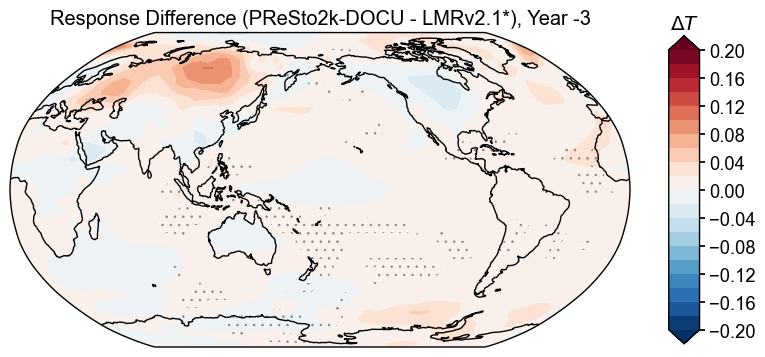

Insignificance differs - Cooling: 0
Insignificance differs - Warming: 216
Both insignificant - Cooling: 2646
Both insignificant - Warming: 2337
Both significant - Cooling: 0
Both significant - Warming: 93


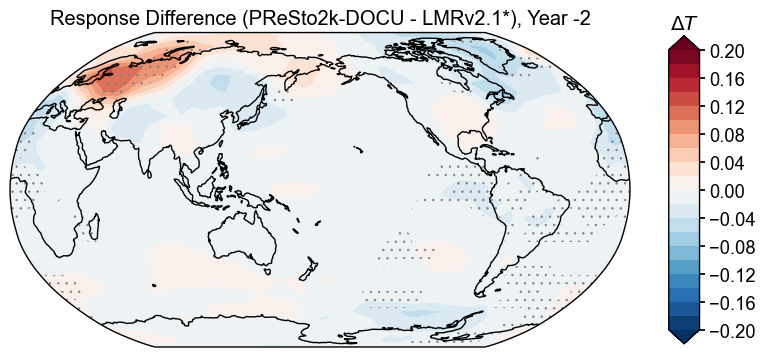

Insignificance differs - Cooling: 177
Insignificance differs - Warming: 174
Both insignificant - Cooling: 2448
Both insignificant - Warming: 2461
Both significant - Cooling: 21
Both significant - Warming: 11


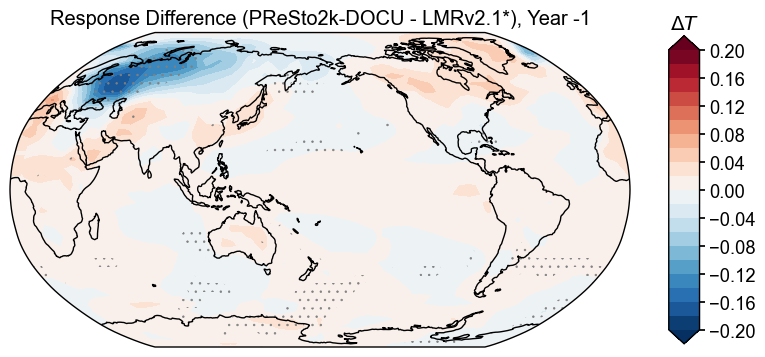

Insignificance differs - Cooling: 219
Insignificance differs - Warming: 8
Both insignificant - Cooling: 2301
Both insignificant - Warming: 2638
Both significant - Cooling: 126
Both significant - Warming: 0


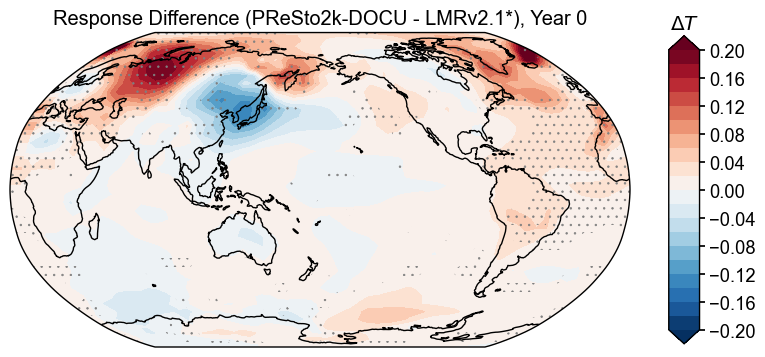

Insignificance differs - Cooling: 635
Insignificance differs - Warming: 9
Both insignificant - Cooling: 839
Both insignificant - Warming: 2637
Both significant - Cooling: 1172
Both significant - Warming: 0


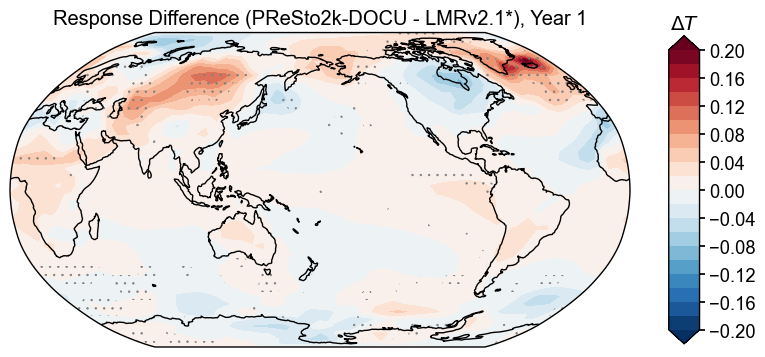

Insignificance differs - Cooling: 283
Insignificance differs - Warming: 0
Both insignificant - Cooling: 434
Both insignificant - Warming: 2646
Both significant - Cooling: 1929
Both significant - Warming: 0


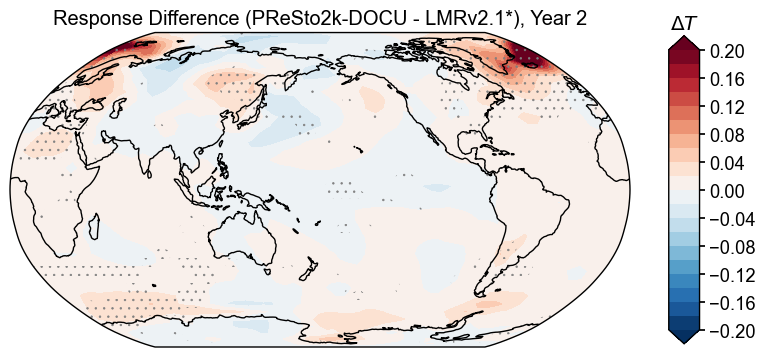

Insignificance differs - Cooling: 383
Insignificance differs - Warming: 0
Both insignificant - Cooling: 746
Both insignificant - Warming: 2646
Both significant - Cooling: 1517
Both significant - Warming: 0


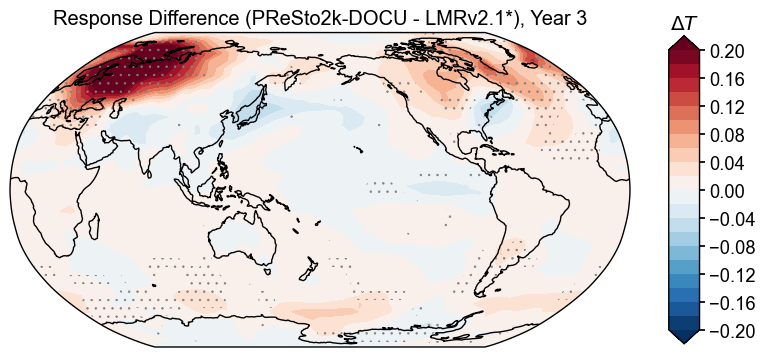

Insignificance differs - Cooling: 475
Insignificance differs - Warming: 3
Both insignificant - Cooling: 553
Both insignificant - Warming: 2643
Both significant - Cooling: 1618
Both significant - Warming: 0


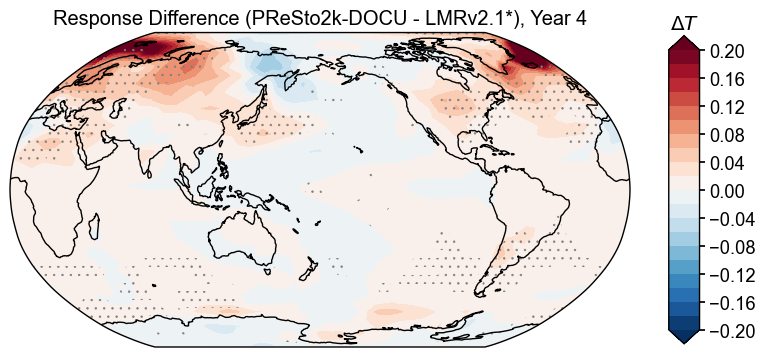

Insignificance differs - Cooling: 490
Insignificance differs - Warming: 0
Both insignificant - Cooling: 792
Both insignificant - Warming: 2646
Both significant - Cooling: 1364
Both significant - Warming: 0


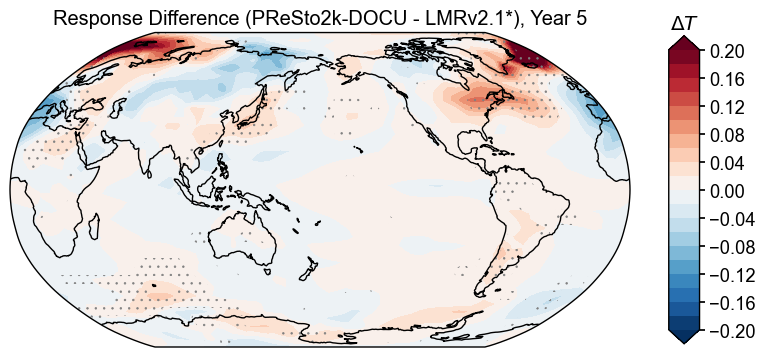

Insignificance differs - Cooling: 331
Insignificance differs - Warming: 0
Both insignificant - Cooling: 704
Both insignificant - Warming: 2646
Both significant - Cooling: 1611
Both significant - Warming: 0


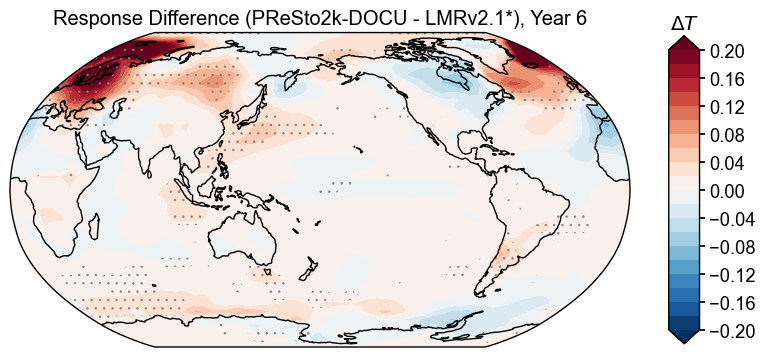

Insignificance differs - Cooling: 413
Insignificance differs - Warming: 0
Both insignificant - Cooling: 855
Both insignificant - Warming: 2646
Both significant - Cooling: 1378
Both significant - Warming: 0


In [33]:
plot_difference_ins( dp_results['top30_composite_dp'],lmr_results['top30_composite_lmr'], dp_results['sig_warm_30_dp'], dp_results['sig_cool_30_dp'], lmr_results['sig_warm_30_lmr'], lmr_results['sig_cool_30_lmr'], 'PReSto2k-DOCU', 'LMRv2.1*', pdb=lmr_docu_diff)

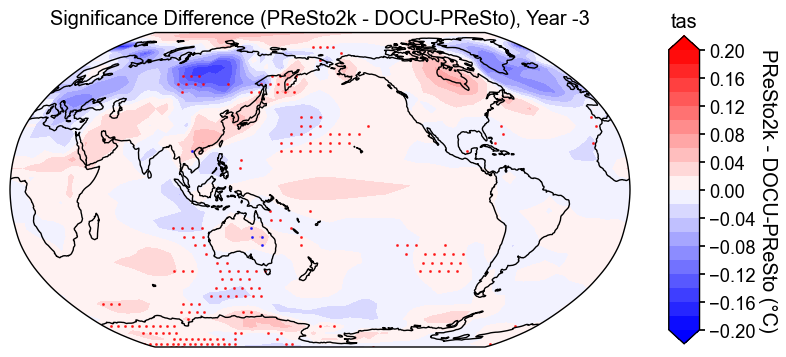

Cooling differences: 5
Warming differences: 200
Points significant (common)  both: Cooling=0, Warming=210


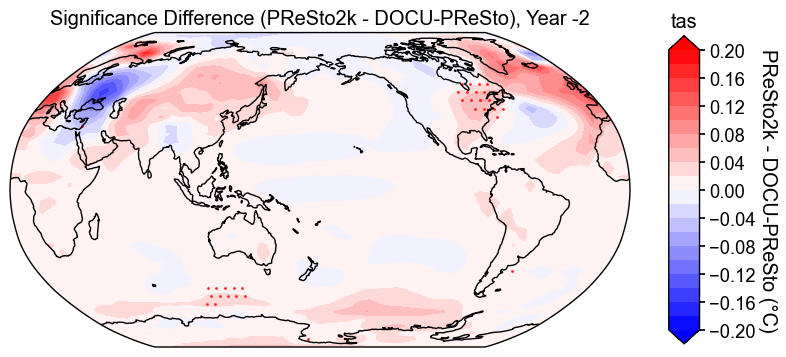

Cooling differences: 0
Warming differences: 35
Points significant (common)  both: Cooling=0, Warming=0


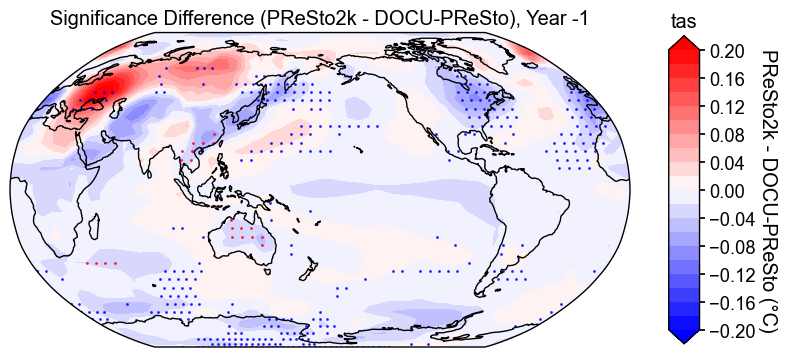

Cooling differences: 360
Warming differences: 22
Points significant (common)  both: Cooling=263, Warming=0


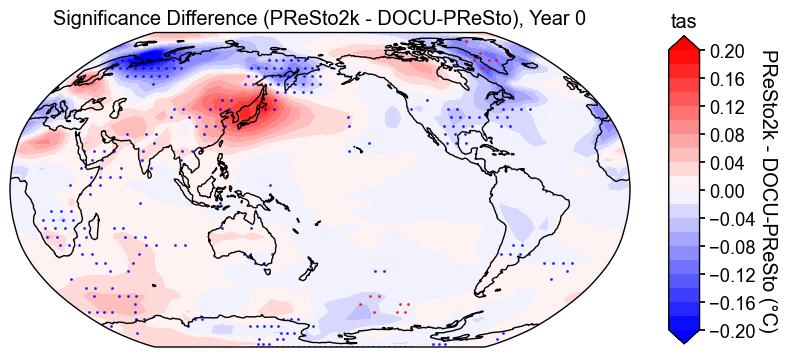

Cooling differences: 290
Warming differences: 15
Points significant (common)  both: Cooling=503, Warming=15


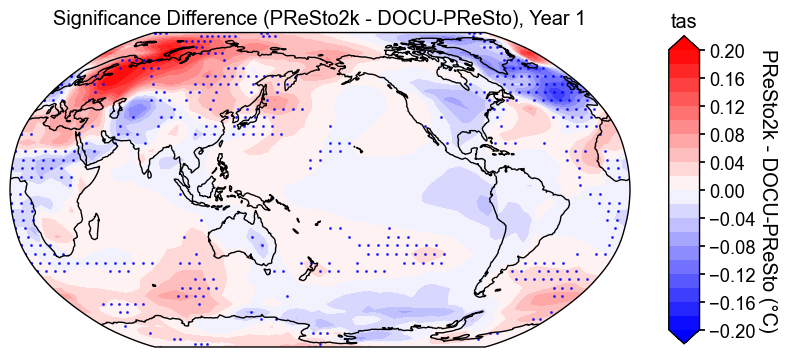

Cooling differences: 484
Warming differences: 0
Points significant (common)  both: Cooling=803, Warming=0


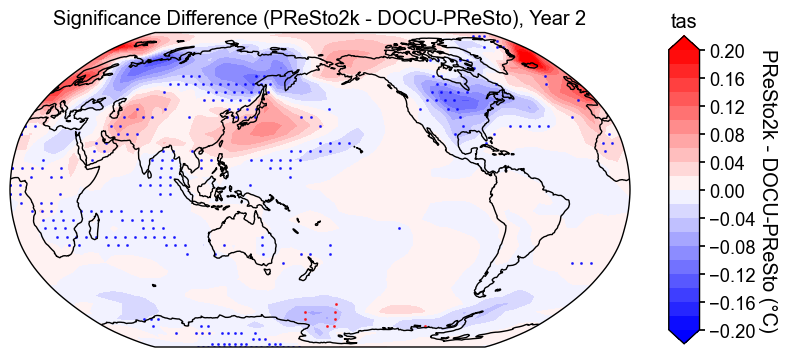

Cooling differences: 283
Warming differences: 8
Points significant (common)  both: Cooling=338, Warming=6


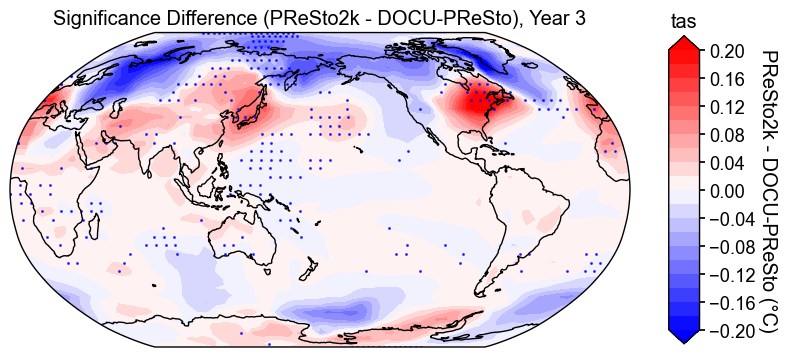

Cooling differences: 288
Warming differences: 0
Points significant (common)  both: Cooling=413, Warming=0


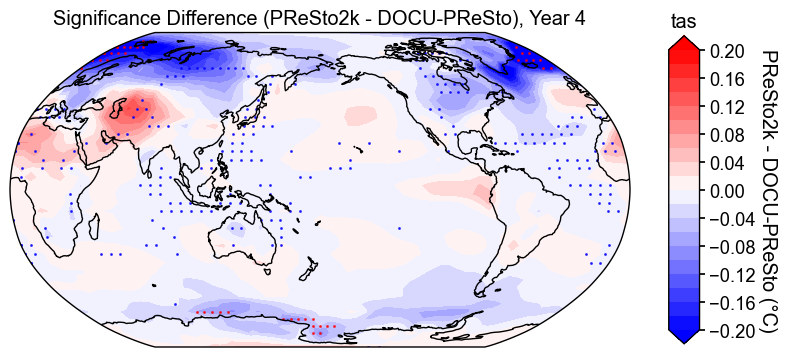

Cooling differences: 242
Warming differences: 44
Points significant (common)  both: Cooling=387, Warming=0


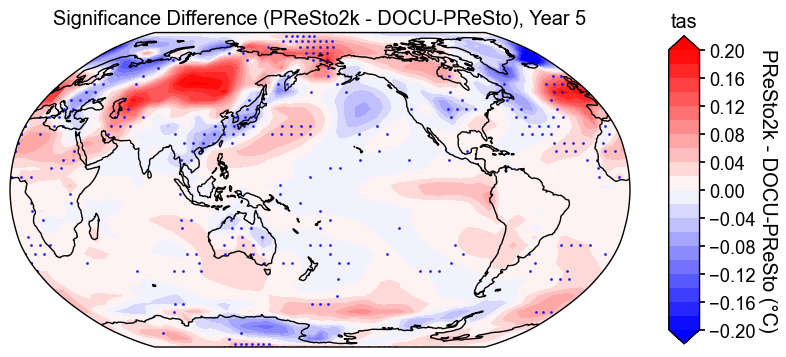

Cooling differences: 313
Warming differences: 0
Points significant (common)  both: Cooling=708, Warming=0


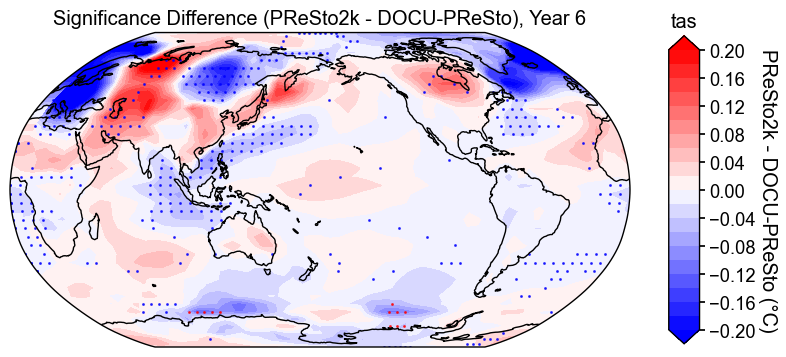

Cooling differences: 347
Warming differences: 12
Points significant (common)  both: Cooling=670, Warming=0


In [59]:
plot_difference(pc_results['top10_composite_pc'], dp_results['top10_composite_dp'], pc_results['sig_warm_10_pc'], pc_results['sig_cool_10_pc'], dp_results['sig_warm_10_dp'], dp_results['sig_cool_10_dp'], 'PReSto2k', 'DOCU-PReSto')

In [55]:
lmr_ts = res_lmr.recons['tas_gm']
pc_ts = res_pc.recons['tas_gm']
dp_ts = res_dp.recons['tas_gm']

In [54]:
def sea_composite_ensemble(ens_ts, eruption_years, window=(-3, 6)):
    """
    Calculate Superposed Epoch Analysis composite for ensemble time series.
    
    Parameters
    ----------
    ens_ts : EnsTS object
        Ensemble time series with .time and .value (nt, nEns)
    eruption_years : array-like
        List of eruption years
    window : tuple
        (start_lag, end_lag) relative to eruption year. Default (-3, 6)
        
    Returns
    -------
    composite_ts : EnsTS object
        Composite time series with shape (window_length, nEns)
        Contains baseline-removed, epoch-averaged response
    """
    start_lag, end_lag = window
    window_length = end_lag - start_lag + 1
    lags = np.arange(start_lag, end_lag + 1)
    
    # Initialize array to store composites: (n_eruptions, window_length, nEns)
    composites = []
    
    for year in eruption_years:
        # Find indices for this eruption window
        window_mask = (ens_ts.time >= year + start_lag) & (ens_ts.time <= year + end_lag)
        baseline_mask = (ens_ts.time >= year - 3) & (ens_ts.time <= year - 1)
        
        if np.sum(window_mask) == window_length and np.sum(baseline_mask) == 3:
            # Extract window for all ensemble members
            window_data = ens_ts.value[window_mask, :]  # (window_length, nEns)
            
            # Calculate baseline (mean of years -3, -2, -1) for each ensemble member
            baseline = np.mean(ens_ts.value[baseline_mask, :], axis=0)  # (nEns,)
            
            # Remove baseline from each year in the window
            window_anomaly = window_data - baseline[np.newaxis, :]
            
            composites.append(window_anomaly)
    
    # Stack all eruptions and average: (n_eruptions, window_length, nEns) -> (window_length, nEns)
    composites = np.array(composites)  # (n_eruptions, window_length, nEns)
    composite_mean = np.mean(composites, axis=0)  # (window_length, nEns)
    
    # Create EnsTS object for output
    composite_ts = cfr.EnsTS(
        time=lags,
        value=composite_mean,
        value_name=ens_ts.value_name
    )
    
    return composite_ts



In [135]:

# Usage example:
# For top 10 eruptions
lmr_sea_top10 = sea_composite_ensemble(lmr_ts, top10_years)
pc_sea_top10 = sea_composite_ensemble(pc_ts, top10_years)
dp_sea_top10 = sea_composite_ensemble(dp_ts, top10_years)

# For top 20 eruptions
lmr_sea_top20 = sea_composite_ensemble(lmr_ts, top20_years)
pc_sea_top20 = sea_composite_ensemble(pc_ts, top20_years)
dp_sea_top20 = sea_composite_ensemble(dp_ts, top20_years)

# For top 30 eruptions
lmr_sea_top30 = sea_composite_ensemble(lmr_ts, top30_years)
pc_sea_top30 = sea_composite_ensemble(pc_ts, top30_years)
dp_sea_top30 = sea_composite_ensemble(dp_ts, top30_years)

(<Figure size 1200x400 with 1 Axes>,
 <Axes: xlabel='Year (CE)', ylabel='tas_gm'>)

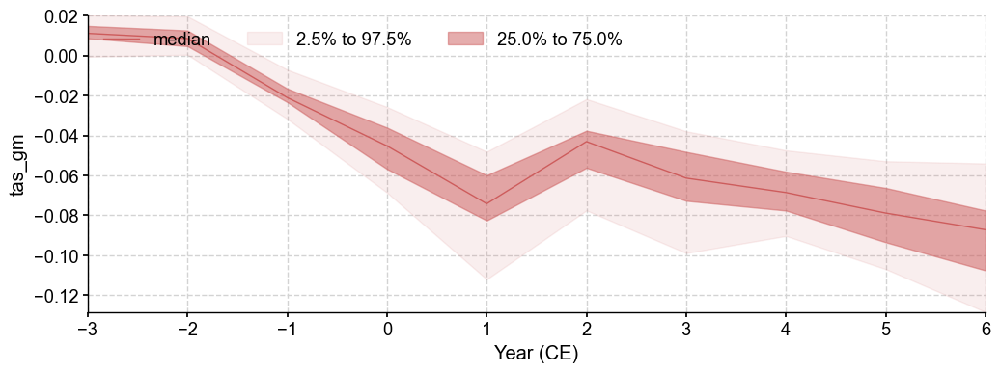

In [58]:
lmr_sea_top10.plot_qs()

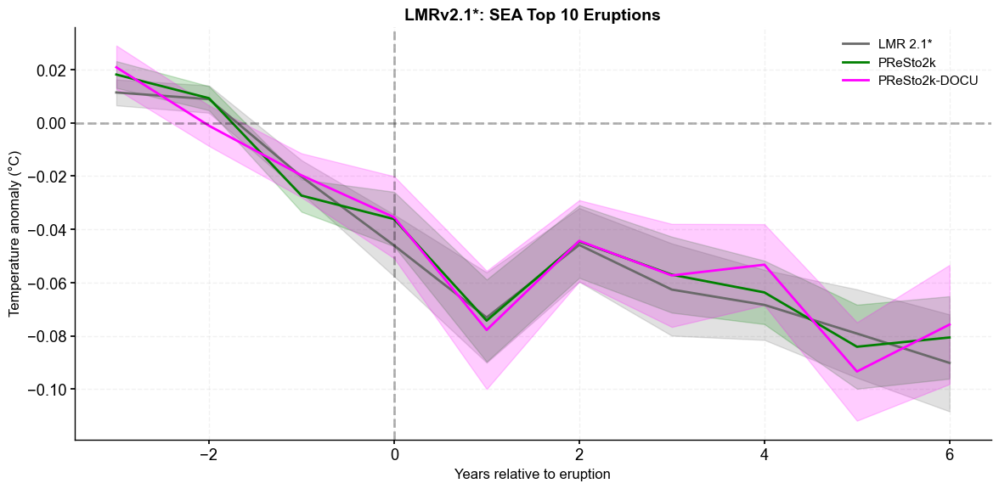

In [71]:
fig, ax = plt.subplots(figsize=(12, 6))

# Calculate mean and standard deviation for each reconstruction
for ens_ts, color, label in [(lmr_sea_top10, 'dimgray', 'LMR 2.1*'),
                               (pc_sea_top10, 'green', 'PReSto2k'),
                               (dp_sea_top10, 'magenta', 'PReSto2k-DOCU')]:
    
    mean = ens_ts.mean
    std = ens_ts.std
    lags = ens_ts.time
    
    # Plot mean line with shaded std
    ax.plot(lags, mean, color=color, linewidth=2, label=label)
    ax.fill_between(lags, mean - std, mean + std, color=color, alpha=0.2)

ax.axhline(0, color='k', linestyle='--', alpha=0.3)
ax.axvline(0, color='k', linestyle='--', alpha=0.3)
ax.set_xlabel('Years relative to eruption', fontsize=12)
ax.set_ylabel('Temperature anomaly (°C)', fontsize=12)
ax.set_title('LMRv2.1*: SEA Top 10 Eruptions', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()

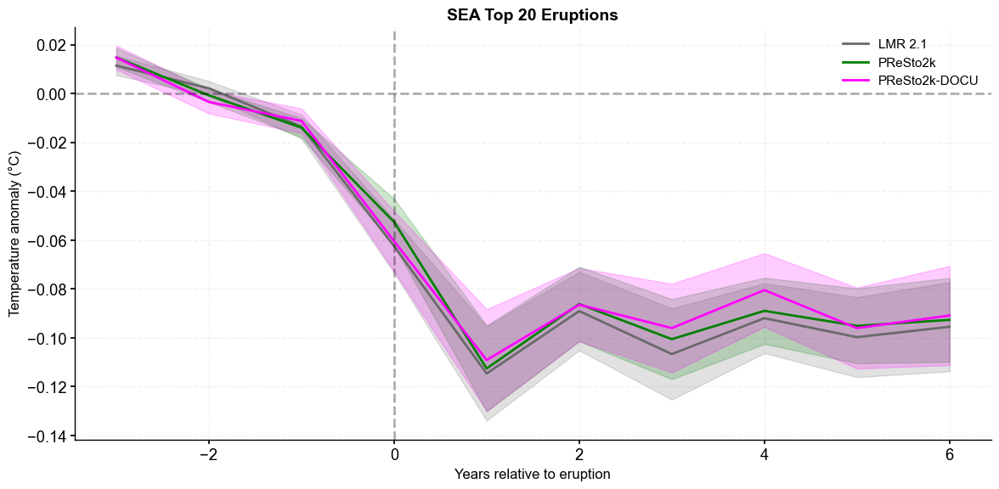

In [136]:
fig, ax = plt.subplots(figsize=(12, 6))

# Calculate mean and standard deviation for each reconstruction
for ens_ts, color, label in [(lmr_sea_top20, 'dimgray', 'LMR 2.1'),
                               (pc_sea_top20, 'green', 'PReSto2k'),
                               (dp_sea_top20, 'magenta', 'PReSto2k-DOCU')]:
    
    mean = ens_ts.mean
    std = ens_ts.std
    lags = ens_ts.time
    
    # Plot mean line with shaded std
    ax.plot(lags, mean, color=color, linewidth=2, label=label)
    ax.fill_between(lags, mean - std, mean + std, color=color, alpha=0.2)

ax.axhline(0, color='k', linestyle='--', alpha=0.3)
ax.axvline(0, color='k', linestyle='--', alpha=0.3)
ax.set_xlabel('Years relative to eruption', fontsize=12)
ax.set_ylabel('Temperature anomaly (°C)', fontsize=12)
ax.set_title('SEA Top 20 Eruptions', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()

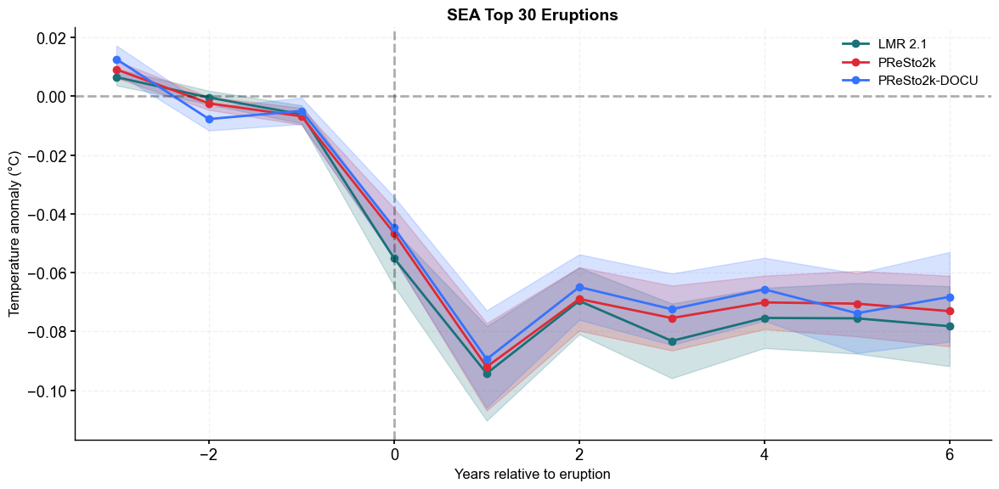

In [137]:
fig, ax = plt.subplots(figsize=(12, 6))

# Calculate mean and standard deviation for each reconstruction
for ens_ts, color, label in [(lmr_sea_top30, '#197278', 'LMR 2.1'),
                               (pc_sea_top30, '#df2935', 'PReSto2k'),
                               (dp_sea_top30, '#3772ff', 'PReSto2k-DOCU')]:
    
    mean = ens_ts.mean
    std = ens_ts.std
    lags = ens_ts.time
    
    # Plot mean line with shaded std
    ax.plot(lags, mean, color=color, linewidth=2, marker = 'o', label=label)
    ax.fill_between(lags, mean - std, mean + std, color=color, alpha=0.2)

ax.axhline(0, color='k', linestyle='--', alpha=0.3)
ax.axvline(0, color='k', linestyle='--', alpha=0.3)
ax.set_xlabel('Years relative to eruption', fontsize=12)
ax.set_ylabel('Temperature anomaly (°C)', fontsize=12)
ax.set_title('SEA Top 30 Eruptions', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()